##Phase 1A: the abstract-section classifier

1. Problem and goal: Predict whether an abstract sentence is background, objective, methods, results, or conclusions.
2. Dataset: PubMed 20k RCT, with numbers preserved.
Inspect the raw files: Understand how abstract IDs, sentences, labels, and abstract boundaries are represented.
3. Parse the data: Preserve abstract IDs and sentence order.
4. Check data quality: Missing values, unexpected labels, and overlap between splits.
5. Explore the training data: Label counts, sentence lengths, and abstract lengths.
Observations and next steps.

Download PubMed 20k RCT.
Parse it into a dataframe.
Explore labels, sentence lengths, class balance, and abstract structure.
Create the PyTorch Dataset and DataLoader.
Build the first section-classification baseline.
Expand it into Biomedical Information Extraction.

In [4]:
!git clone https://github.com/Franck-Dernoncourt/pubmed-rct.git

fatal: destination path 'pubmed-rct' already exists and is not an empty directory.


In [5]:
# Standard library
import json
import random
import sys
from pathlib import Path
from functools import partial
from copy import deepcopy

# Data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PyTorch
import torch
from torch import nn
from torch.utils.data import DataLoader

# Baselines and evaluation
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

# Colab
from google.colab import drive

In [6]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [7]:

import sys
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/Portfolio_Project/Abstract_Classifier"
)

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

In [8]:
from functools import partial
from torch.utils.data import DataLoader

from abstract_classifier.data import (
    load_abstract_sentences,
    AbstractSentenceDataset,
    PositionDataset,
    collate_batch,
    collate_position_batch,
    make_seeded_train_loader,
)

from abstract_classifier.training import (
    train_one_epoch,
    evaluate,
    train_weighted_epoch,
    train_position_epoch,
    evaluate_position,
    run_seeded_cnn_epoch,
    run_seeded_position_epoch,
)



# import importlib
# import abstract_classifier.models as model_definitions

# importlib.reload(model_definitions)

from abstract_classifier.models import (
    AbstractClassifier,
    CNNAbstractClassifier,
    PositionCNN,
)


from abstract_classifier.reproducibility import set_random_seed


from abstract_classifier.checkpointing import (
    capture_random_states,
    restore_random_states,
    save_checkpoint,
)


import re


from abstract_classifier.preprocessing import (
    tokenize,
    prepare_raw_sentence,
)


from abstract_classifier.inference import (
    predict_section,
    predict_abstract,
    predict_raw_abstract,
)

In [9]:
from pathlib import Path

data_dir = Path("pubmed-rct/PubMed_20k_RCT")
train_path = data_dir / "train.txt"
train_df = load_abstract_sentences(data_dir / "train.txt")
validation_df = load_abstract_sentences(data_dir / "dev.txt")
test_df = load_abstract_sentences(data_dir / "test.txt")

train_df.head()

,abstract_id,sentence,label,sentence_number
0,24293578,To investigate the efficacy of 6 weeks of dail...,OBJECTIVE,0
1,24293578,A total of 125 patients with primary knee OA w...,METHODS,1
2,24293578,Outcome measures included pain reduction and i...,METHODS,2
3,24293578,Pain was assessed using the visual analog pain...,METHODS,3
4,24293578,Secondary outcome measures included the Wester...,METHODS,4


In [10]:
print(train_path.resolve())
print("File exists:", train_path.exists())


/content/pubmed-rct/PubMed_20k_RCT/train.txt
File exists: True


In [11]:


splits = {
    "train": train_df,
    "validation": validation_df,
    "test": test_df,
}

for name, df in splits.items():
    print(name, '.....')
    print(df.isna().sum())


text_columns = ["abstract_id", "sentence", "label"]

for name, df in splits.items():
    print(name)
    for column in text_columns:
        empty_count = df[column].str.strip().eq("").sum()
        print(column, empty_count)


#number of labels
expected_labels = {
    "BACKGROUND", "OBJECTIVE", "METHODS", "RESULTS", "CONCLUSIONS"
}

for name, df in splits.items():
    observed_labels = set(df["label"].dropna())
    print(name)
    print("Unexpected labels:", observed_labels - expected_labels)
    print("Absent labels:", expected_labels - observed_labels)

#Duplicate records
for name, df in splits.items():
    duplicate_count = df.duplicated(
        subset=["abstract_id", "sentence_number"]
    ).sum()
    print(name, duplicate_count)

train_ids = set(train_df["abstract_id"])
validation_ids = set(validation_df["abstract_id"])
test_ids = set(test_df["abstract_id"])

print("Train / validation overlap:", len(train_ids & validation_ids))
print("Train / test overlap:", len(train_ids & test_ids))
print("Validation / test overlap:", len(validation_ids & test_ids))

#Sentence Order
# Check sentence numbering within each training abstract.
invalid_abstract_ids = []

for abstract_id, group_df in train_df.groupby("abstract_id"):
    expected_order = list(range(len(group_df)))
    actual_order = group_df["sentence_number"].tolist()

    if actual_order != expected_order:
        invalid_abstract_ids.append(abstract_id)

print("Abstracts with invalid numbering:", len(invalid_abstract_ids))
print("First few affected IDs:", invalid_abstract_ids[:5])






train .....
abstract_id        0
sentence           0
label              0
sentence_number    0
dtype: int64
validation .....
abstract_id        0
sentence           0
label              0
sentence_number    0
dtype: int64
test .....
abstract_id        0
sentence           0
label              0
sentence_number    0
dtype: int64
train
abstract_id 0
sentence 0
label 0
validation
abstract_id 0
sentence 0
label 0
test
abstract_id 0
sentence 0
label 0
train
Unexpected labels: set()
Absent labels: set()
validation
Unexpected labels: set()
Absent labels: set()
test
Unexpected labels: set()
Absent labels: set()
train 0
validation 0
test 0
Train / validation overlap: 0
Train / test overlap: 0
Validation / test overlap: 0
Abstracts with invalid numbering: 0
First few affected IDs: []


In [12]:
label_summary = pd.DataFrame({
    "count": train_df["label"].value_counts(),
    "percentage": train_df["label"].value_counts(normalize=True) * 100,
})

print(label_summary)

train_df["word_count"] = train_df["sentence"].str.split().str.len()

print(train_df[["sentence", "word_count"]].head())
print(train_df["word_count"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))



             count  percentage
label                         
METHODS      59353   32.966563
RESULTS      57953   32.188958
CONCLUSIONS  27168   15.089980
BACKGROUND   21727   12.067874
OBJECTIVE    13839    7.686625
                                            sentence  word_count
0  To investigate the efficacy of 6 weeks of dail...          49
1  A total of 125 patients with primary knee OA w...          27
2  Outcome measures included pain reduction and i...          15
3  Pain was assessed using the visual analog pain...          14
4  Secondary outcome measures included the Wester...          35
count    180040.000000
mean         26.338436
std          15.386976
min           1.000000
50%          23.000000
90%          45.000000
95%          55.000000
99%          80.000000
max         296.000000
Name: word_count, dtype: float64


In [13]:
train_df.nlargest(5, "word_count")[["sentence", "word_count"]]


,sentence,word_count
122524,Patients in the antegrade group achieved bette...,296
71510,There were significant differences in body tem...,275
129612,Significant associations emerged between negle...,246
164330,Eyes undergoing both treatments had improved b...,243
106909,"The scores on sexual self-confidence , sexual ...",242


In [14]:

train_df.nsmallest(55, "word_count")[["sentence", "label", "word_count"]]

# 4921, 6305, 14803, 16686

,sentence,label,word_count
4921,I.,METHODS,1
6305,I.,METHODS,1
14803,I.,METHODS,1
16557,I.,METHODS,1
16686,I.,METHODS,1
34852,I.,METHODS,1
35924,I.,METHODS,1
36807,I.,METHODS,1
49339,I.,METHODS,1
51981,I.,METHODS,1


In [15]:
with train_path.open(encoding="utf-8") as file:
    for line_number, line in enumerate(file, start=1):
        if "24306696" in line:
            print(line_number, repr(line))


suspect_id = train_df.loc[62134, "abstract_id"]

print(
    train_df.loc[
        train_df["abstract_id"] == suspect_id,
        ["sentence_number", "label", "sentence"]
    ].to_string(index=False)
)

72524 'CONCLUSIONS\t24306696\n'
 sentence_number       label                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              sentence
               0  BACKGROUND                                                                                                                                                                                                                                                                                                    Recombinant human bone morphogenetic protein-2 ( rhBMP-2 ) applied on an absorbable collagen sponge improves open tibial fracture-hea

In [16]:
suspect_id = train_df.loc[4921, "abstract_id"]

print(
    train_df.loc[
        train_df["abstract_id"] == suspect_id,
        ["sentence_number", "label", "sentence"]
    ].to_string(index=False)
)

suspect_id = train_df.loc[6305, "abstract_id"]

print(
    train_df.loc[
        train_df["abstract_id"] == suspect_id,
        ["sentence_number", "label", "sentence"]
    ].to_string(index=False)
)

suspect_id = train_df.loc[16686, "abstract_id"]

print(
    train_df.loc[
        train_df["abstract_id"] == suspect_id,
        ["sentence_number", "label", "sentence"]
    ].to_string(index=False)
)



 sentence_number       label                                                                                                                                                                                                                                                                                                             sentence
               0   OBJECTIVE                                                                                  This study aims to determine the outcome of double-bundle anterior cruciate ligament ( ACL ) reconstruction using an allograft in comparison with ACL reconstruction using a double-bundle autograft or a single-bundle allograft .
               1     METHODS A total of 424 patients who accepted primary ACL reconstructions were divided randomly into three groups : double-bundle technique with autograft ( DB-AU group , n = 154 ) , double-bundle technique with allograft ( DB-AL group , n = 128 ) , and single-bundle technique with allograft ( SB group 

In [17]:
longest_sentence = train_df.loc[
    train_df["word_count"].idxmax(), "sentence"
]

with train_path.open(encoding="utf-8") as file:
    matches = [
        line.rstrip("\r\n")
        for line in file
        if "\t" in line
        and line.rstrip("\r\n").split("\t", 1)[1] == longest_sentence
    ]

print("Exact matching sentence lines:", len(matches))

Exact matching sentence lines: 1


In [18]:
abstract_lengths = train_df.groupby("abstract_id").size()

print(abstract_lengths.describe())

count    15000.000000
mean        12.002667
std          3.072516
min          4.000000
25%         10.000000
50%         12.000000
75%         14.000000
max         31.000000
dtype: float64


##MAJORITY PREDICTION

In [19]:
#MAJORITY

majority_label = train_df["label"].value_counts().idxmax()
print(majority_label)

majority_predictions = [majority_label] * len(validation_df)



METHODS


In [20]:
validation_df["label"][0]

'BACKGROUND'

In [21]:
print(validation_df["label"])
err_count = 0
methods_count = 0
for i in range (0, len(validation_df)):
  if (majority_predictions[i]!=validation_df["label"].iloc[i]):
    err_count = err_count + 1
  if(validation_df["label"].iloc[i]=='METHODS'):
    methods_count = methods_count+1
print(err_count, methods_count)
print(err_count/len(validation_df)*100)
accuracy = (len(validation_df) - err_count) / len(validation_df)
precision = methods_count/len(validation_df)
print(f"Validation accuracy: {accuracy:.2%}")
print(f"Precision: {precision:.2%}")


recall = 1.0
methods_f1 = 2 * precision * recall / (precision + recall)

print(f"METHODS F1: {methods_f1:.2%}")

macro_f1 = (methods_f1 + 0 + 0 + 0 + 0) / 5

print(f"Macro-F1: {macro_f1:.2%}")

0         BACKGROUND
1         BACKGROUND
2          OBJECTIVE
3            METHODS
4            METHODS
            ...     
30207        RESULTS
30208        RESULTS
30209        RESULTS
30210    CONCLUSIONS
30211    CONCLUSIONS
Name: label, Length: 30212, dtype: object
20248 9964
67.01972726069113
Validation accuracy: 32.98%
Precision: 32.98%
METHODS F1: 49.60%
Macro-F1: 9.92%


##TF-IDF + Logistic Regression


In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()

# Learn vocabulary and IDF statistics from training sentences,
# then convert those sentences into feature vectors.
X_train = vectorizer.fit_transform(train_df["sentence"])

# Apply the same representation to validation sentences.
X_validation = vectorizer.transform(validation_df["sentence"])

y_train = train_df["label"]
y_validation = validation_df["label"]

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_validation.shape)

Training matrix: (180040, 57996)
Validation matrix: (30212, 57996)


In [23]:
feature_names = vectorizer.get_feature_names_out()

print("Vocabulary size:", len(feature_names))
print("First 20 terms:", feature_names[:20])


first_row = X_train.getrow(0)

print("Sentence:", train_df["sentence"].iloc[0])
print("Label:", train_df["label"].iloc[0])

for column_index, score in zip(first_row.indices, first_row.data):
    print(f"{feature_names[column_index]}: {score:.3f}")

Vocabulary size: 57996
First 20 terms: ['00' '000' '0000' '000000072' '000000752' '000001' '00000154108'
 '00000244' '000002832' '000003103' '000003177' '000003262' '000004511'
 '000005' '00000500' '000005983' '000007972' '00001' '000012012'
 '000012287']
Sentence: To investigate the efficacy of 6 weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at 12 weeks in older adults with moderate to severe knee osteoarthritis ( OA ) .
Label: OBJECTIVE
to: 0.118
investigate: 0.166
the: 0.134
efficacy: 0.128
of: 0.097
weeks: 0.254
daily: 0.145
low: 0.278
dose: 0.134
oral: 0.154
prednisolone: 0.234
in: 0.156
improving: 0.181
pain: 0.127
mobility: 0.216
and: 0.093
systemic: 0.187
grade: 0.176
inflammation: 0.185
short: 0.167
term: 0.152
whether: 0.148
effect: 0.127
would: 0.179
be: 0.113
sustained: 0.191
at: 0.089
12: 0.119
older: 0.169
adults: 0.159
with: 0.065
moderate: 0.161
sev

In [24]:
from sklearn.linear_model import LogisticRegression

classifier = LogisticRegression(max_iter=1000)

classifier.fit(X_train, y_train)

validation_predictions_lr = classifier.predict(X_validation)

In [25]:
accuracy_lr = (validation_predictions_lr == y_validation).mean()

print(f"Validation accuracy: {accuracy_lr:.2%}")

Validation accuracy: 80.92%


In [26]:
from sklearn.metrics import classification_report

label_order = [
    "BACKGROUND",
    "OBJECTIVE",
    "METHODS",
    "RESULTS",
    "CONCLUSIONS",
]

print(classification_report(
    y_validation,
    validation_predictions_lr,
    labels=label_order,
    digits=3,
    zero_division=0,
))

              precision    recall  f1-score   support

  BACKGROUND      0.626     0.642     0.634      3449
   OBJECTIVE      0.689     0.519     0.592      2376
     METHODS      0.857     0.907     0.881      9964
     RESULTS      0.875     0.877     0.876      9841
 CONCLUSIONS      0.744     0.727     0.736      4582

    accuracy                          0.809     30212
   macro avg      0.758     0.734     0.744     30212
weighted avg      0.806     0.809     0.807     30212



In [27]:
from sklearn.metrics import confusion_matrix
#for LogReg

print('Logistic Regression')
matrix = confusion_matrix(
    y_validation,
    validation_predictions_lr,
    labels=label_order,
)

confusion_df = pd.DataFrame(
    matrix,
    index=label_order,
    columns=label_order,
)

confusion_df.index.name = "Actual"
confusion_df.columns.name = "Predicted"

display(confusion_df)

Logistic Regression


Predicted,BACKGROUND,OBJECTIVE,METHODS,RESULTS,CONCLUSIONS
Actual,,,,,
BACKGROUND,2215,405,317,42,470
OBJECTIVE,707,1233,210,25,201
METHODS,149,75,9035,611,94
RESULTS,45,7,776,8633,380
CONCLUSIONS,420,69,206,555,3332


OBJECTIVE has the lowest recall and F1.

In [28]:
# Keep predictions alongside the corresponding validation sentences.
validation_results = validation_df.copy()
validation_results["predicted_label"] = validation_predictions_lr

# Select actual OBJECTIVE sentences predicted as BACKGROUND.
objective_as_background = validation_results.loc[
    (validation_results["label"] == "OBJECTIVE")
    & (validation_results["predicted_label"] == "BACKGROUND")
]

print("Number of matching errors:", len(objective_as_background))

# Print five reproducibly sampled examples without truncating the text.
examples = objective_as_background.sample(
    n=min(5, len(objective_as_background)),
    random_state=42,
)

for _, row in examples.iterrows():
    print(f"\nAbstract ID: {row['abstract_id']}")
    print(f"Sentence number: {row['sentence_number']}")
    print(f"Actual: {row['label']} | Predicted: {row['predicted_label']}")
    print(row["sentence"])

Number of matching errors: 707

Abstract ID: 24963091
Sentence number: 2
Actual: OBJECTIVE | Predicted: BACKGROUND
Here , we addressed the question of whether NMES can modify upper esophageal sphincter ( UES ) dynamics .

Abstract ID: 24565089
Sentence number: 1
Actual: OBJECTIVE | Predicted: BACKGROUND
Several analgesic techniques have been advocated .

Abstract ID: 25416724
Sentence number: 2
Actual: OBJECTIVE | Predicted: BACKGROUND
However , MetS has also been associated with higher estradiol ( E2 ) levels , which is bone protective .

Abstract ID: 24799054
Sentence number: 1
Actual: OBJECTIVE | Predicted: BACKGROUND
We report the activity and safety results of biweekly combination of trastuzumab , docetaxel and gemcitabine as first-line therapy in HER2-positive advanced breast cancer .

Abstract ID: 24941010
Sentence number: 1
Actual: OBJECTIVE | Predicted: BACKGROUND
We hypothesize that strict maintenance of normoglycemia during cardiac surgery preserves postoperative cognitive f

In [29]:
from abstract_classifier.preprocessing import (
    tokenize,
    prepare_raw_sentence,
)

example_sentence = train_df["sentence"].iloc[0]
example_tokens = tokenize(example_sentence)

print(example_sentence)
print(example_tokens)
print("Number of tokens:", len(example_tokens))

To investigate the efficacy of 6 weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at 12 weeks in older adults with moderate to severe knee osteoarthritis ( OA ) .
['to', 'investigate', 'the', 'efficacy', 'of', '6', 'weeks', 'of', 'daily', 'low-dose', 'oral', 'prednisolone', 'in', 'improving', 'pain', ',', 'mobility', ',', 'and', 'systemic', 'low-grade', 'inflammation', 'in', 'the', 'short', 'term', 'and', 'whether', 'the', 'effect', 'would', 'be', 'sustained', 'at', '12', 'weeks', 'in', 'older', 'adults', 'with', 'moderate', 'to', 'severe', 'knee', 'osteoarthritis', '(', 'oa', ')', '.']
Number of tokens: 49


In [30]:
vocab = {"<PAD>": 0, "<UNK>": 1}

for sentence in train_df["sentence"]:
    for token in tokenize(sentence):
        if token not in vocab:
            vocab[token] = len(vocab)

print("Vocabulary size:", len(vocab))
print(list(vocab.items())[:15])

Vocabulary size: 102910
[('<PAD>', 0), ('<UNK>', 1), ('to', 2), ('investigate', 3), ('the', 4), ('efficacy', 5), ('of', 6), ('6', 7), ('weeks', 8), ('daily', 9), ('low-dose', 10), ('oral', 11), ('prednisolone', 12), ('in', 13), ('improving', 14)]


In [31]:
example_ids = [
    vocab.get(token, vocab["<UNK>"])
    for token in example_tokens
]

print(example_ids)
print("Number of IDs:", len(example_ids))

[2, 3, 4, 5, 6, 7, 8, 6, 9, 10, 11, 12, 13, 14, 15, 16, 17, 16, 18, 19, 20, 21, 13, 4, 22, 23, 18, 24, 4, 25, 26, 27, 28, 29, 30, 8, 13, 31, 32, 33, 34, 2, 35, 36, 37, 38, 39, 40, 41]
Number of IDs: 49


In [32]:
# Supply the padding ID; DataLoader will supply the batch.
text_collator = partial(
    collate_batch,
    pad_id=vocab["<PAD>"],
)

position_collator = partial(
    collate_position_batch,
    pad_id=vocab["<PAD>"],
)

In [33]:
label_to_id = {
    "BACKGROUND": 0,
    "OBJECTIVE": 1,
    "METHODS": 2,
    "RESULTS": 3,
    "CONCLUSIONS": 4,
}

id_to_label = {
    label_id: label
    for label, label_id in label_to_id.items()
}

print(id_to_label)

{0: 'BACKGROUND', 1: 'OBJECTIVE', 2: 'METHODS', 3: 'RESULTS', 4: 'CONCLUSIONS'}


In [34]:
sentence = train_df["sentence"].iloc[0]
label = train_df["label"].iloc[0]

token_ids = [
    vocab.get(token, vocab["<UNK>"])
    for token in tokenize(sentence)
]
label_id = label_to_id[label]

print("Token IDs:", token_ids)
print("Label:", label)
print("Label ID:", label_id)

Token IDs: [2, 3, 4, 5, 6, 7, 8, 6, 9, 10, 11, 12, 13, 14, 15, 16, 17, 16, 18, 19, 20, 21, 13, 4, 22, 23, 18, 24, 4, 25, 26, 27, 28, 29, 30, 8, 13, 31, 32, 33, 34, 2, 35, 36, 37, 38, 39, 40, 41]
Label: OBJECTIVE
Label ID: 1


In [35]:
train_dataset = AbstractSentenceDataset(
    train_df, vocab, label_to_id
)

validation_dataset = AbstractSentenceDataset(
    validation_df, vocab, label_to_id
)

In [36]:
token_ids, label_id = train_dataset[0]

print("Number of examples:", len(train_dataset))
print("Token IDs:", token_ids)
print("Token tensor shape:", token_ids.shape)
print("Label ID:", label_id.item())
print("Label:", id_to_label[label_id.item()])

Number of examples: 180040
Token IDs: tensor([ 2,  3,  4,  5,  6,  7,  8,  6,  9, 10, 11, 12, 13, 14, 15, 16, 17, 16,
        18, 19, 20, 21, 13,  4, 22, 23, 18, 24,  4, 25, 26, 27, 28, 29, 30,  8,
        13, 31, 32, 33, 34,  2, 35, 36, 37, 38, 39, 40, 41])
Token tensor shape: torch.Size([49])
Label ID: 1
Label: OBJECTIVE


In [37]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    collate_fn=text_collator,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=64,
    shuffle=False,
    collate_fn=text_collator,
)

In [38]:
batch_tokens, batch_labels = next(iter(train_loader))

print("Token shape:", batch_tokens.shape)
print("Label shape:", batch_labels.shape)

print("First sentence IDs:", batch_tokens[0])
print("Its label ID:", batch_labels[0].item())
print("Its actual length:", (batch_tokens[0] != vocab["<PAD>"]).sum().item())

Token shape: torch.Size([64, 73])
Label shape: torch.Size([64])
First sentence IDs: tensor([    4,  1689,   474,     6, 36708,    47, 11524,    18,  1468,  1851,
           41,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0])
Its label ID: 4
Its actual length: 11


In [39]:
model = AbstractClassifier(
    vocab_size=len(vocab),
    embedding_dim=64,
    num_classes=len(label_to_id),
    pad_id=vocab["<PAD>"],
)

with torch.no_grad():
    scores = model(batch_tokens)

print("Output shape:", scores.shape)
print("First sentence's scores:", scores[0])

batch_tokens, batch_labels = next(iter(train_loader))

with torch.no_grad():
    scores = model(batch_tokens)

print("Input shape:", batch_tokens.shape)
print("Label shape:", batch_labels.shape)
print("Output shape:", scores.shape)

Output shape: torch.Size([64, 5])
First sentence's scores: tensor([ 0.0830, -0.2771,  0.0078,  0.2296, -0.3740])
Input shape: torch.Size([64, 73])
Label shape: torch.Size([64])
Output shape: torch.Size([64, 5])


In [40]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

#MEAN Embedding

In [41]:
# history = []


# Mean embedding model

# for epoch in range(5, 6):
#     train_loss, train_accuracy = train_one_epoch(
#         model, train_loader, loss_fn, optimizer
#     )

#     val_loss, val_accuracy = evaluate(
#         model, validation_loader, loss_fn
#     )

#     history.append({
#         "epoch": epoch,
#         "train_loss": train_loss,
#         "train_accuracy": train_accuracy,
#         "validation_loss": val_loss,
#         "validation_accuracy": val_accuracy,
#     })

#     print(
#         f"Epoch {epoch} | "
#         f"Train loss: {train_loss:.4f}, accuracy: {train_accuracy:.2%} | "
#         f"Validation loss: {val_loss:.4f}, accuracy: {val_accuracy:.2%}"
#     )

In [42]:
# checkpoint = {
#     "model_state_dict": model.state_dict(),
#     "optimizer_state_dict": optimizer.state_dict(),
#     "vocab": vocab,
#     "label_to_id": label_to_id,
#     "embedding_dim": model.embedding.embedding_dim,
#     "pad_id": model.pad_id,
#     "epochs_completed": 4,
#     "validation_accuracy": val_accuracy,
#     "validation_loss": val_loss,
#     "tokenizer": "lowercase_then_whitespace_split",
# }

# torch.save(checkpoint, "abstract_classifier_epoch4.pt")

In [43]:
# from google.colab import files

# files.download("abstract_classifier_epoch4.pt")

In [44]:
checkpoint_dir = Path(
    "/content/drive/MyDrive/Portfolio_Project/Abstract_Classifier/checkpoints"
)
checkpoint_dir.mkdir(parents=True, exist_ok=True)

restored_path = checkpoint_dir / "abstract_classifier_epoch4.pt"

mean_checkpoint = torch.load(
    restored_path,
    map_location="cpu",
    weights_only=True,
)

restored_model = AbstractClassifier(
    vocab_size=len(mean_checkpoint["vocab"]),
    embedding_dim=mean_checkpoint["embedding_dim"],
    num_classes=len(mean_checkpoint["label_to_id"]),
    pad_id=mean_checkpoint["pad_id"],
)

restored_model.load_state_dict(mean_checkpoint["model_state_dict"])

<All keys matched successfully>

In [45]:
restored_loss, restored_accuracy = evaluate(
    restored_model, validation_loader, loss_fn
)

print(f"Restored validation loss: {restored_loss:.4f}")
print(f"Restored validation accuracy: {restored_accuracy:.2%}")

Restored validation loss: 0.5384
Restored validation accuracy: 80.71%


In [46]:
saved_vocab = mean_checkpoint["vocab"]
saved_id_to_label = {
    label_id: label
    for label, label_id in mean_checkpoint["label_to_id"].items()
}

In [47]:
# Text-only model: classify one sentence.
label = predict_section(
    "We randomly assigned 350 patients to treatment or placebo .",
    model=restored_model,
    vocab=saved_vocab,
    id_to_label=saved_id_to_label,
)

print(label)

METHODS


In [48]:
mean_predictions = []
mean_labels = []

restored_model.eval()

with torch.no_grad():
    for batch_tokens, batch_labels in validation_loader:
        scores = restored_model(batch_tokens)
        predictions = scores.argmax(dim=1)

        mean_predictions.extend(predictions.cpu().tolist())
        mean_labels.extend(batch_labels.cpu().tolist())

In [49]:
from sklearn.metrics import classification_report

class_ids = list(range(len(label_to_id)))
class_names = [id_to_label[i] for i in class_ids]

print(classification_report(
    mean_labels,
    mean_predictions,
    labels=class_ids,
    target_names=class_names,
    digits=3,
    zero_division=0,
))

              precision    recall  f1-score   support

  BACKGROUND      0.645     0.586     0.614      3449
   OBJECTIVE      0.633     0.574     0.602      2376
     METHODS      0.880     0.882     0.881      9964
     RESULTS      0.849     0.894     0.871      9841
 CONCLUSIONS      0.747     0.743     0.745      4582

    accuracy                          0.807     30212
   macro avg      0.751     0.736     0.743     30212
weighted avg      0.803     0.807     0.805     30212



In [50]:
# from sklearn.metrics import f1_score


# tfidf_macro_f1 = f1_score(
#     y_validation,
#     validation_predictions_lr,
#     average="macro",
# )

# print(f"TF-IDF macro-F1: {tfidf_macro_f1:.3f}")

##CNN

In [51]:
cnn_model = CNNAbstractClassifier(
    vocab_size=len(vocab),
    embedding_dim=64,
    num_filters=32,
    num_classes=len(label_to_id),
    pad_id=vocab["<PAD>"],
)

batch_tokens, batch_labels = next(iter(train_loader))

with torch.no_grad():
    scores = cnn_model(batch_tokens)

print("Input shape:", batch_tokens.shape)
print("Output shape:", scores.shape)

Input shape: torch.Size([64, 60])
Output shape: torch.Size([64, 5])


In [52]:
from pathlib import Path

checkpoint_dir = Path(
    "/content/drive/MyDrive/Portfolio_Project/Abstract_Classifier/checkpoints"
)

In [53]:
from copy import deepcopy

#from zero

cnn_optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)

cnn_history = []
best_cnn_loss = float("inf")
best_cnn_checkpoint = None

In [54]:
from copy import deepcopy

#load prev model

checkpoint = torch.load(
    checkpoint_dir / "cnn_latest.pt",
    map_location="cpu",
    weights_only=True,
)

# Restore the exact mappings used during training.
vocab = checkpoint["vocab"]
label_to_id = checkpoint["label_to_id"]

cnn_model = CNNAbstractClassifier(
    vocab_size=len(vocab),
    embedding_dim=checkpoint["embedding_dim"],
    num_filters=checkpoint["num_filters"],
    num_classes=len(label_to_id),
    pad_id=checkpoint["pad_id"],
)
cnn_model.load_state_dict(checkpoint["model_state_dict"])

cnn_optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)
cnn_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

loss_fn = nn.CrossEntropyLoss()

cnn_history = checkpoint["history"]
best_cnn_loss = checkpoint["best_validation_loss"]

best_cnn_checkpoint = torch.load(
    checkpoint_dir / "cnn_best.pt",
    map_location="cpu",
    weights_only=True,
)

start_epoch = checkpoint["epochs_completed"] + 1

In [55]:
# #additional_epochs = 2
#epochs not inside a function
# #for epoch in range(start_epoch, start_epoch + additional_epochs):
#     # Same training, validation, and checkpoint-saving body.
# for epoch in range(1, 6):
#     train_loss, train_accuracy = train_one_epoch(
#         cnn_model, train_loader, loss_fn, cnn_optimizer
#     )

#     val_loss, val_accuracy = evaluate(
#         cnn_model, validation_loader, loss_fn
#     )

#     cnn_history.append({
#         "epoch": epoch,
#         "train_loss": train_loss,
#         "train_accuracy": train_accuracy,
#         "validation_loss": val_loss,
#         "validation_accuracy": val_accuracy,
#     })

#     improved = val_loss < best_cnn_loss

#     if improved:
#         best_cnn_loss = val_loss

#         best_cnn_checkpoint = {
#             "model_state_dict": deepcopy(cnn_model.state_dict()),
#             "optimizer_state_dict": deepcopy(cnn_optimizer.state_dict()),
#             "vocab": vocab.copy(),
#             "label_to_id": label_to_id.copy(),
#             "embedding_dim": cnn_model.embedding.embedding_dim,
#             "num_filters": cnn_model.conv.out_channels,
#             "kernel_size": cnn_model.conv.kernel_size[0],
#             "padding": cnn_model.conv.padding[0],
#             "pad_id": cnn_model.pad_id,
#             "epochs_completed": epoch,
#             "validation_loss": val_loss,
#             "validation_accuracy": val_accuracy,
#             "tokenizer": "lowercase_then_whitespace_split",
#         }

#         torch.save(best_cnn_checkpoint, "cnn_best.pt")

#     latest_checkpoint = {
#       **best_cnn_checkpoint,  # Reuse vocabulary and architecture metadata.
#       "model_state_dict": cnn_model.state_dict(),
#       "optimizer_state_dict": cnn_optimizer.state_dict(),
#       "epochs_completed": epoch,
#       "validation_loss": val_loss,
#       "validation_accuracy": val_accuracy,
#       "best_validation_loss": best_cnn_loss,
#       "history": cnn_history,
#     }

#     torch.save(latest_checkpoint, "cnn_latest.pt")

#     print(
#         f"Epoch {epoch} | "
#         f"Train loss: {train_loss:.4f}, accuracy: {train_accuracy:.2%} | "
#         f"Validation loss: {val_loss:.4f}, accuracy: {val_accuracy:.2%}"
#         + (" | Best saved" if improved else ""),
#         flush=True,
#     )

In [56]:
# #temp


# latest_checkpoint = {
#     **best_cnn_checkpoint,
#     "model_state_dict": cnn_model.state_dict(),
#     "optimizer_state_dict": cnn_optimizer.state_dict(),
#     "epochs_completed": epoch,
#     "validation_loss": val_loss,
#     "validation_accuracy": val_accuracy,
#     "best_validation_loss": best_cnn_loss,
#     "history": cnn_history,
# }

# torch.save(latest_checkpoint, "cnn_latest.pt")

In [57]:
# from google.colab import files

# files.download("cnn_best.pt")
# files.download("cnn_latest.pt")

In [58]:
cnn_model.load_state_dict(
    best_cnn_checkpoint["model_state_dict"]
)

print("Selected epoch:", best_cnn_checkpoint["epochs_completed"])

Selected epoch: 3


In [59]:
cnn_predictions = []
cnn_labels = []

cnn_model.eval()

with torch.no_grad():
    for tokens, labels in validation_loader:
        scores = cnn_model(tokens)

        cnn_predictions.extend(scores.argmax(dim=1).cpu().tolist())
        cnn_labels.extend(labels.cpu().tolist())

print(classification_report(
    cnn_labels,
    cnn_predictions,
    labels=class_ids,
    target_names=class_names,
    digits=3,
    zero_division=0,
))

              precision    recall  f1-score   support

  BACKGROUND      0.601     0.714     0.653      3449
   OBJECTIVE      0.761     0.471     0.582      2376
     METHODS      0.876     0.905     0.890      9964
     RESULTS      0.882     0.861     0.872      9841
 CONCLUSIONS      0.724     0.747     0.735      4582

    accuracy                          0.811     30212
   macro avg      0.769     0.740     0.746     30212
weighted avg      0.814     0.811     0.809     30212



In [60]:
print('CNN Confusion')
cnn_confusion = pd.DataFrame(
    confusion_matrix(
        cnn_labels,
        cnn_predictions,
        labels=class_ids,
    ),
    index=class_names,
    columns=class_names,
)

cnn_confusion.index.name = "Actual"
cnn_confusion.columns.name = "Predicted"

display(cnn_confusion)

CNN Confusion


Predicted,BACKGROUND,OBJECTIVE,METHODS,RESULTS,CONCLUSIONS
Actual,,,,,
BACKGROUND,2464,283,209,45,448
OBJECTIVE,901,1119,153,22,181
METHODS,207,49,9020,557,131
RESULTS,47,4,767,8478,545
CONCLUSIONS,481,16,149,512,3424


##CLASS WEIGHTED CROSS ENTROPY

In [61]:
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from torch import nn

##########CLASS WEIGHTED CROSS ENTROPY##############


import torch
from torch import nn
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")


checkpoint_dir = Path(
    "/content/drive/MyDrive/Portfolio_Project/Abstract_Classifier/checkpoints"
)
checkpoint_dir.mkdir(parents=True, exist_ok=True)

# Keep weights aligned with the numerical class IDs.
class_names = [
    label for label, class_id in
    sorted(label_to_id.items(), key=lambda item: item[1])
]

counts = train_df["label"].value_counts().reindex(class_names)

# Smaller classes receive larger weights.
class_weights = torch.tensor(
    (len(train_df) / (len(class_names) * counts)).to_numpy(),
    dtype=torch.float32,
)

print("Class weights:")
for name, weight in zip(class_names, class_weights):
    print(f"{name}: {weight.item():.3f}")

torch.manual_seed(42)

weighted_cnn = CNNAbstractClassifier(
    vocab_size=len(vocab),
    embedding_dim=64,
    num_filters=32,
    num_classes=len(label_to_id),
    pad_id=vocab["<PAD>"],
)

weighted_optimizer = torch.optim.Adam(
    weighted_cnn.parameters(), lr=0.001
)

# Sum weighted losses so we can calculate the correct weighted mean.
weighted_loss_sum = nn.CrossEntropyLoss(
    weight=class_weights, reduction="sum"
)

# Use ordinary validation loss for comparison with earlier runs.
validation_loss_fn = nn.CrossEntropyLoss()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Class weights:
BACKGROUND: 1.657
OBJECTIVE: 2.602
METHODS: 0.607
RESULTS: 0.621
CONCLUSIONS: 1.325


In [62]:
# weighted_history = []
# best_val_loss = float("inf")

# for epoch in range(1, 6):
#   train_loss, train_accuracy = train_weighted_epoch(
#     weighted_cnn,
#     train_loader,
#     weighted_optimizer,
#     weighted_loss_sum=weighted_loss_sum,
#     class_weights=class_weights,
# )

#     val_loss, val_accuracy = evaluate(
#         weighted_cnn, validation_loader, validation_loss_fn
#     )

#     weighted_history.append({
#         "epoch": epoch,
#         "weighted_train_loss": train_loss,
#         "train_accuracy": train_accuracy,
#         "validation_loss": val_loss,
#         "validation_accuracy": val_accuracy,
#     })

#     improved = val_loss < best_val_loss
#     if improved:
#         best_val_loss = val_loss

#     checkpoint = {
#         "model_state_dict": weighted_cnn.state_dict(),
#         "optimizer_state_dict": weighted_optimizer.state_dict(),
#         "vocab": vocab,
#         "label_to_id": label_to_id,
#         "embedding_dim": 64,
#         "num_filters": 32,
#         "kernel_size": 3,
#         "padding": 1,
#         "pad_id": vocab["<PAD>"],
#         "class_weights": class_weights,
#         "epochs_completed": epoch,
#         "validation_loss": val_loss,
#         "validation_accuracy": val_accuracy,
#         "best_validation_loss": best_val_loss,
#         "history": weighted_history,
#         "tokenizer": "lowercase_then_whitespace_split",
#     }

#     # Written immediately: no deepcopy needed.
#     torch.save(
#         checkpoint, checkpoint_dir / "cnn_weighted_latest.pt"
#     )

#     if improved:
#         torch.save(
#             checkpoint, checkpoint_dir / "cnn_weighted_best.pt"
#         )

#     print(
#         f"Epoch {epoch} | "
#         f"Weighted train loss: {train_loss:.4f}, "
#         f"accuracy: {train_accuracy:.2%} | "
#         f"Validation loss: {val_loss:.4f}, "
#         f"accuracy: {val_accuracy:.2%}"
#         + (" | Best saved" if improved else ""),
#         flush=True,
#     )

In [63]:
from sklearn.metrics import classification_report

weighted_checkpoint = torch.load(
    checkpoint_dir / "cnn_weighted_best.pt",
    map_location="cpu",
    weights_only=True,
)

weighted_cnn.load_state_dict(weighted_checkpoint["model_state_dict"])
weighted_cnn.eval()

weighted_predictions = []
weighted_labels = []

with torch.no_grad():
    for tokens, labels in validation_loader:
        scores = weighted_cnn(tokens)
        weighted_predictions.extend(scores.argmax(dim=1).tolist())
        weighted_labels.extend(labels.tolist())

print("Selected epoch:", weighted_checkpoint["epochs_completed"])

print(classification_report(
    weighted_labels,
    weighted_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=3,
    zero_division=0,
))

Selected epoch: 3
              precision    recall  f1-score   support

  BACKGROUND      0.599     0.634     0.616      3449
   OBJECTIVE      0.613     0.601     0.607      2376
     METHODS      0.888     0.873     0.880      9964
     RESULTS      0.884     0.827     0.855      9841
 CONCLUSIONS      0.677     0.772     0.721      4582

    accuracy                          0.794     30212
   macro avg      0.732     0.742     0.736     30212
weighted avg      0.800     0.794     0.796     30212



In [64]:
print('weighted CNN Confusion')
weighted_cnn_confusion = pd.DataFrame(
    confusion_matrix(
        weighted_labels,
        weighted_predictions,
        labels=class_ids,
    ),
    index=class_names,
    columns=class_names,
)

weighted_cnn_confusion.index.name = "Actual"
weighted_cnn_confusion.columns.name = "Predicted"

display(weighted_cnn_confusion)

weighted CNN Confusion


Predicted,BACKGROUND,OBJECTIVE,METHODS,RESULTS,CONCLUSIONS
Actual,,,,,
BACKGROUND,2188,642,133,30,456
OBJECTIVE,681,1428,94,12,161
METHODS,238,154,8699,655,218
RESULTS,72,20,756,8142,851
CONCLUSIONS,471,87,115,372,3537


##CNN vs weighted CNN

In this run, inverse-frequency class weighting increased OBJECTIVE recall from 47.1% to 60.1%, but reduced precision and overall macro-F1. The unweighted CNN remained the stronger overall baseline. Different random initializations limit attributing the entire difference to weighting.

In [65]:
# Assumes validation_loader used shuffle=False and validation_df order.
results = validation_df.copy()

id_to_label = {
    class_id: label
    for label, class_id in label_to_id.items()
}

assert len(weighted_predictions) == len(results)
assert weighted_labels == [
    label_to_id[label] for label in results["label"]
]

results["predicted_label"] = [
    id_to_label[prediction] for prediction in weighted_predictions
]

errors = results.loc[
    (results["label"] == "OBJECTIVE")
    & (results["predicted_label"] == "BACKGROUND")
]

print("OBJECTIVE → BACKGROUND errors:", len(errors))

examples = errors.sample(n=min(5, len(errors)), random_state=42)

for _, error in examples.iterrows():
    print(f"\n{'=' * 70}")
    print(f"Abstract ID: {error['abstract_id']}")

    abstract = results.loc[
        results["abstract_id"] == error["abstract_id"]
    ].sort_values("sentence_number")

    for _, row in abstract.iterrows():
        marker = (
            ">>>"
            if row["sentence_number"] == error["sentence_number"]
            else "   "
        )

        print(
            f"\n{marker} Sentence {row['sentence_number']} | "
            f"Actual: {row['label']} | "
            f"Predicted: {row['predicted_label']}"
        )
        print(row["sentence"])

OBJECTIVE → BACKGROUND errors: 681

Abstract ID: 25286782

>>> Sentence 0 | Actual: OBJECTIVE | Predicted: BACKGROUND
Administration of many drugs including magnesium sulfate ( MS ) has considerable influences on pregnancy outcomes .

    Sentence 1 | Actual: OBJECTIVE | Predicted: OBJECTIVE
The present study investigates the effects of MS administration on reaching the active phase of labor in women with premature rupture of membrane ( PROM ) and subsequent fetal complications .

    Sentence 2 | Actual: METHODS | Predicted: METHODS
A double blind , randomized , placebo-controlled trial was performed among primipara women referred to the PROM center in Tehran , Iran between March 2010 and August 2012 .

    Sentence 3 | Actual: METHODS | Predicted: RESULTS
Patients were equally allocated into two groups ; the intervention group who received MS ( n = 46 ) and the control ( placebo ) group ( n = 46 ) .

    Sentence 4 | Actual: METHODS | Predicted: METHODS
Both groups received a cortico

In [66]:
#test

# Two examples: one METHODS, one OBJECTIVE.
example_scores = torch.zeros(2, len(label_to_id))

example_labels = torch.tensor([
    label_to_id["METHODS"],
    label_to_id["OBJECTIVE"],
])

# Calculate a separate loss for each example.
plain_losses = nn.CrossEntropyLoss(reduction="none")(
    example_scores, example_labels
)

weighted_losses = nn.CrossEntropyLoss(
    weight=class_weights,
    reduction="none",
)(example_scores, example_labels)

print("Unweighted losses:", plain_losses)
print("Class weights:", class_weights[example_labels])
print("Weighted losses:", weighted_losses)

Unweighted losses: tensor([1.6094, 1.6094])
Class weights: tensor([0.6067, 2.6019])
Weighted losses: tensor([0.9764, 4.1876])


In [67]:
example = errors.iloc[0]

abstract = results.loc[
    results["abstract_id"] == example["abstract_id"]
].sort_values("sentence_number")

print("Misclassified sentence:")
print(example["sentence"])

print("\nFull abstract:")
for _, row in abstract.iterrows():
    marker = ">>>" if row["sentence_number"] == example["sentence_number"] else ""

    print(
        f"\n{marker} Sentence {row['sentence_number']} "
        f"| Actual: {row['label']} "
        f"| Predicted: {row['predicted_label']}"
    )
    print(row["sentence"])

Misclassified sentence:
To estimate age at attaining Tanner stages in Ugandan/Zimbabwean HIV-infected children initiating antiretroviral therapy ( ART ) in older childhood and investigate predictors of delayed puberty , particularly age at ART initiation .

Full abstract:

>>> Sentence 0 | Actual: OBJECTIVE | Predicted: BACKGROUND
To estimate age at attaining Tanner stages in Ugandan/Zimbabwean HIV-infected children initiating antiretroviral therapy ( ART ) in older childhood and investigate predictors of delayed puberty , particularly age at ART initiation .

 Sentence 1 | Actual: METHODS | Predicted: METHODS
Observational analysis within a randomized trial .

 Sentence 2 | Actual: METHODS | Predicted: METHODS
Tanner staging was assessed every 24 weeks from 10 years of age , menarche every 12 weeks and height every 4-6 weeks .

 Sentence 3 | Actual: METHODS | Predicted: METHODS
Age at attaining different Tanner stages was estimated using normal interval regression , considering predic

In [68]:
examples = [
    example["sentence"],
    "To estimate the timing of puberty and investigate predictors of delay .",
    "To estimate outcomes and investigate predictors .",
]

weighted_cnn.eval()

with torch.no_grad():
    for sentence in examples:
        ids = [
            vocab.get(token, vocab["<UNK>"])
            for token in tokenize(sentence)
        ]
        inputs = torch.tensor(ids, dtype=torch.long).unsqueeze(0)

        predicted_id = weighted_cnn(inputs).argmax(dim=1).item()

        print(id_to_label[predicted_id], "|", sentence)

BACKGROUND | To estimate age at attaining Tanner stages in Ugandan/Zimbabwean HIV-infected children initiating antiretroviral therapy ( ART ) in older childhood and investigate predictors of delayed puberty , particularly age at ART initiation .
OBJECTIVE | To estimate the timing of puberty and investigate predictors of delay .
OBJECTIVE | To estimate outcomes and investigate predictors .


In [69]:
original = example["sentence"]

probes = {
    "Original": original,
    "Replace opening": original.replace(
        "To estimate", "This study aimed to estimate", 1
    ),
    "Simplify one technical phrase": original.replace(
        "Tanner stages", "stages of puberty"
    ),
    "Simplify population description": original.replace(
        "Ugandan/Zimbabwean HIV-infected children",
        "children with HIV"
    ),
}

weighted_cnn.eval()

with torch.no_grad():
    for name, sentence in probes.items():
        ids = [
            vocab.get(token, vocab["<UNK>"])
            for token in tokenize(sentence)
        ]
        inputs = torch.tensor(ids, dtype=torch.long).unsqueeze(0)

        predicted_id = weighted_cnn(inputs).argmax(dim=1).item()

        print(f"{name}: {id_to_label[predicted_id]}")
        print(sentence)
        print()

Original: BACKGROUND
To estimate age at attaining Tanner stages in Ugandan/Zimbabwean HIV-infected children initiating antiretroviral therapy ( ART ) in older childhood and investigate predictors of delayed puberty , particularly age at ART initiation .

Replace opening: BACKGROUND
This study aimed to estimate age at attaining Tanner stages in Ugandan/Zimbabwean HIV-infected children initiating antiretroviral therapy ( ART ) in older childhood and investigate predictors of delayed puberty , particularly age at ART initiation .

Simplify one technical phrase: BACKGROUND
To estimate age at attaining stages of puberty in Ugandan/Zimbabwean HIV-infected children initiating antiretroviral therapy ( ART ) in older childhood and investigate predictors of delayed puberty , particularly age at ART initiation .

Simplify population description: BACKGROUND
To estimate age at attaining Tanner stages in children with HIV initiating antiretroviral therapy ( ART ) in older childhood and investigate p

In [70]:
example = errors.iloc[30]

abstract = results.loc[
    results["abstract_id"] == example["abstract_id"]
].sort_values("sentence_number")

print("Misclassified sentence:")
print(example["sentence"])

print("\nFull abstract:")
for _, row in abstract.iterrows():
    marker = ">>>" if row["sentence_number"] == example["sentence_number"] else ""

    print(
        f"\n{marker} Sentence {row['sentence_number']} "
        f"| Actual: {row['label']} "
        f"| Predicted: {row['predicted_label']}"
    )
    print(row["sentence"])

Misclassified sentence:
Community-based efforts to prevent adolescent problem behaviors are essential to promote public health and achieve collective impact community wide .

Full abstract:

>>> Sentence 0 | Actual: OBJECTIVE | Predicted: BACKGROUND
Community-based efforts to prevent adolescent problem behaviors are essential to promote public health and achieve collective impact community wide .

 Sentence 1 | Actual: OBJECTIVE | Predicted: OBJECTIVE
OBJECTIVE To test whether the Communities That Care ( CTC ) prevention system reduced levels of risk and adolescent problem behaviors community wide 8 years after implementation of CTC .

 Sentence 2 | Actual: METHODS | Predicted: METHODS
A community-randomized trial was performed in 24 small towns in 7 states , matched within state , assigned randomly to a control or intervention group in 2003 .

 Sentence 3 | Actual: METHODS | Predicted: METHODS
All fifth-grade students attending public schools in study communities in 2003-2004 who rece

In [71]:
example = errors.iloc[33]

abstract = results.loc[
    results["abstract_id"] == example["abstract_id"]
].sort_values("sentence_number")

print("Misclassified sentence:")
print(example["sentence"])

print("\nFull abstract:")
for _, row in abstract.iterrows():
    marker = ">>>" if row["sentence_number"] == example["sentence_number"] else ""

    print(
        f"\n{marker} Sentence {row['sentence_number']} "
        f"| Actual: {row['label']} "
        f"| Predicted: {row['predicted_label']}"
    )
    print(row["sentence"])

Misclassified sentence:
A common challenge for the utilization of fNIRS in these areas is a stable and reliable investigation of the spatio-temporal hemodynamic patterns .

Full abstract:

 Sentence 0 | Actual: OBJECTIVE | Predicted: OBJECTIVE
Functional near-infrared spectroscopy ( fNIRS ) is an emerging technique for the in vivo assessment of functional activity of the cerebral cortex as well as in the field of brain-computer interface ( BCI ) research .

>>> Sentence 1 | Actual: OBJECTIVE | Predicted: BACKGROUND
A common challenge for the utilization of fNIRS in these areas is a stable and reliable investigation of the spatio-temporal hemodynamic patterns .

 Sentence 2 | Actual: OBJECTIVE | Predicted: CONCLUSIONS
However , the recorded patterns may be influenced and superimposed by signals generated from physiological processes , resulting in an inaccurate estimation of the cortical activity .

 Sentence 3 | Actual: OBJECTIVE | Predicted: BACKGROUND
Up to now only a few studies hav

In [72]:
examples = [
    example["sentence"],
    "Community-based efforts to prevent adolescent problem behaviors.",
    "To promote public health and achieve collective impact community wide preventing adolescent problem behaviors are essential .",
    "To promote public health and achieve collective impact community wide, preventing adolescent problem behaviors are essential .",
    "To promote public health and achieve collective impact community wide, preventing adolescent problem behaviors using community-based efforts are essential .",
    "Community-based efforts to prevent adolescent problem behaviors are essential in promoting public health .",
]

weighted_cnn.eval()

with torch.no_grad():
    for sentence in examples:
        ids = [
            vocab.get(token, vocab["<UNK>"])
            for token in tokenize(sentence)
        ]
        inputs = torch.tensor(ids, dtype=torch.long).unsqueeze(0)

        predicted_id = weighted_cnn(inputs).argmax(dim=1).item()

        print(id_to_label[predicted_id], "|", sentence)

BACKGROUND | A common challenge for the utilization of fNIRS in these areas is a stable and reliable investigation of the spatio-temporal hemodynamic patterns .
BACKGROUND | Community-based efforts to prevent adolescent problem behaviors.
OBJECTIVE | To promote public health and achieve collective impact community wide preventing adolescent problem behaviors are essential .
BACKGROUND | To promote public health and achieve collective impact community wide, preventing adolescent problem behaviors are essential .
BACKGROUND | To promote public health and achieve collective impact community wide, preventing adolescent problem behaviors using community-based efforts are essential .
BACKGROUND | Community-based efforts to prevent adolescent problem behaviors are essential in promoting public health .


In [73]:
# Longer headings come first so "BACKGROUND AND OBJECTIVE"
# is matched before "BACKGROUND".
headings = [
    "BACKGROUND AND OBJECTIVES",
    "BACKGROUND AND OBJECTIVE",
    "MAIN OUTCOMES AND MEASURES",
    "DESIGN SETTING AND PARTICIPANTS",
    "DESIGN, SETTING, AND PARTICIPANTS",
    "TRIAL REGISTRATION",
    "CONCLUSIONS AND RELEVANCE",
    "OBJECTIVES",
    "OBJECTIVE",
    "BACKGROUND",
    "IMPORTANCE",
    "METHODS",
    "RESULTS",
    "CONCLUSIONS",
    "CONCLUSION",
    "PURPOSE",
    "AIMS",
    "AIM",
]


def find_heading(sentence):
    text = sentence.lstrip()

    for heading in headings:
        if text.startswith(heading):
            remainder = text[len(heading):]

            # Require a boundary: avoid matching "AIM" in "AIMING".
            if (
                not remainder
                or remainder[0].isspace()
                or remainder[0] in ":.-"
            ):
                return heading

    return None

In [74]:
heading_audit = train_df.copy()
heading_audit["heading_prefix"] = (
    heading_audit["sentence"].apply(find_heading)
)

flagged = heading_audit.loc[
    heading_audit["heading_prefix"].notna()
]

print("Training sentences:", len(heading_audit))
print("Flagged sentences:", len(flagged))
print(f"Flagged percentage: {len(flagged) / len(heading_audit):.2%}")

print("\nCounts by heading:")
print(flagged["heading_prefix"].value_counts())

Training sentences: 180040
Flagged sentences: 42
Flagged percentage: 0.02%

Counts by heading:
heading_prefix
RESULTS                       26
TRIAL REGISTRATION             7
MAIN OUTCOMES AND MEASURES     2
OBJECTIVE                      2
METHODS                        2
CONCLUSIONS AND RELEVANCE      1
CONCLUSION                     1
CONCLUSIONS                    1
Name: count, dtype: int64


In [75]:
display(pd.crosstab(
    flagged["heading_prefix"],
    flagged["label"],
))

label,BACKGROUND,CONCLUSIONS,METHODS,OBJECTIVE,RESULTS
heading_prefix,,,,,
CONCLUSION,0,0,0,0,1
CONCLUSIONS,0,1,0,0,0
CONCLUSIONS AND RELEVANCE,0,0,0,0,1
MAIN OUTCOMES AND MEASURES,0,0,2,0,0
METHODS,0,0,0,2,0
OBJECTIVE,0,0,1,1,0
RESULTS,1,7,12,0,6
TRIAL REGISTRATION,0,6,0,0,1


In [76]:
for _, row in flagged.sample(
    n=min(10, len(flagged)),
    random_state=42,
).iterrows():
    print(f"\nPrefix: {row['heading_prefix']} | Label: {row['label']}")
    print(row["sentence"])



##This detector found too few candidates to make heading removal a priority, although it does not capture every possible heading format.


Prefix: RESULTS | Label: RESULTS
RESULTS for all IIEF and SEP measures were significantly better for TAD-OaD ( p < 0.001 for all ) compared to PBO and were comparable to those observed during PRN-PDE5I treatment .

Prefix: TRIAL REGISTRATION | Label: CONCLUSIONS
TRIAL REGISTRATION clinicaltrials.gov Identifier : NCT00787579 .

Prefix: TRIAL REGISTRATION | Label: CONCLUSIONS
TRIAL REGISTRATION DETAILS : Clinical Trial Registry-India URL : http://ctri.nic.in , Registration Number : CTRI/2009/091 / 001036 .

Prefix: RESULTS | Label: METHODS
RESULTS ; Curative rate of group A was better than that of group B , otherwise incidence rate of critical illness was less than that of group B.

Prefix: RESULTS | Label: BACKGROUND
RESULTS of the feasibility study on the first 100 enrolled patients are presented .

Prefix: OBJECTIVE | Label: METHODS
OBJECTIVE clinical assessments were made by blinded photographic evaluation .

Prefix: METHODS | Label: OBJECTIVE
METHODS : One hundred cases of VCF were

#CNN+Position

In [77]:
# def add_position_feature(df):
#     result = df.copy()

#     result["total_sentences"] = (
#         result.groupby("abstract_id")["sentence"].transform("size")
#     )

#     # Avoid division by zero for a one-sentence abstract.
#     denominator = (result["total_sentences"] - 1).clip(lower=1)

#     result["relative_position"] = (
#         result["sentence_number"] / denominator
#     )

#     return result

from abstract_classifier.preprocessing import add_position_feature


train_position_df = add_position_feature(train_df)
validation_position_df = add_position_feature(validation_df)

In [78]:
first_id = train_position_df["abstract_id"].iloc[0]

display(
    train_position_df.loc[
        train_position_df["abstract_id"] == first_id,
        ["sentence_number", "total_sentences", "relative_position", "label"],
    ]
)

,sentence_number,total_sentences,relative_position,label
0,0,12,0.000000,OBJECTIVE
1,1,12,0.090909,METHODS
2,2,12,0.181818,METHODS
3,3,12,0.272727,METHODS
4,4,12,0.363636,METHODS
5,5,12,0.454545,METHODS
6,6,12,0.545455,RESULTS
7,7,12,0.636364,RESULTS
8,8,12,0.727273,RESULTS
9,9,12,0.818182,RESULTS


In [79]:


position_train_dataset = PositionDataset(
    train_position_df, vocab, label_to_id
)
position_validation_dataset = PositionDataset(
    validation_position_df, vocab, label_to_id
)

position_train_loader = DataLoader(
    position_train_dataset,
    batch_size=64,
    shuffle=True,
    collate_fn=position_collator,
    generator=torch.Generator().manual_seed(42),
)

position_validation_loader = DataLoader(
    position_validation_dataset,
    batch_size=64,
    shuffle=False,
    collate_fn=position_collator,
)

In [80]:
token_ids, positions, labels = next(iter(position_validation_loader))

print("Token IDs:", token_ids.shape)
print("Positions:", positions.shape)
print("Labels:", labels.shape)

Token IDs: torch.Size([64, 83])
Positions: torch.Size([64])
Labels: torch.Size([64])


In [81]:

torch.manual_seed(42)

position_model = PositionCNN(
    vocab_size=len(vocab),
    embedding_dim=64,
    num_filters=32,
    num_classes=len(label_to_id),
    pad_id=vocab["<PAD>"],
)

position_optimizer = torch.optim.Adam(
    position_model.parameters(), lr=0.001
)
position_loss_fn = nn.CrossEntropyLoss()

In [82]:
# checkpoint_dir.mkdir(parents=True, exist_ok=True)

# position_history = []
# best_position_loss = float("inf")

# for epoch in range(1, 6):
#     train_loss, train_accuracy = train_position_epoch(
#         position_model,
#         position_train_loader,
#         position_loss_fn,
#         position_optimizer,
#     )

#     val_loss, val_accuracy, _, _ = evaluate_position(
#         position_model,
#         position_validation_loader,
#         position_loss_fn,
#     )

#     position_history.append({
#         "epoch": epoch,
#         "train_loss": train_loss,
#         "train_accuracy": train_accuracy,
#         "validation_loss": val_loss,
#         "validation_accuracy": val_accuracy,
#     })

#     improved = val_loss < best_position_loss
#     if improved:
#         best_position_loss = val_loss

#     position_checkpoint = {
#         "model_state_dict": position_model.state_dict(),
#         "optimizer_state_dict": position_optimizer.state_dict(),
#         "vocab": vocab,
#         "label_to_id": label_to_id,
#         "embedding_dim": 64,
#         "num_filters": 32,
#         "kernel_size": 3,
#         "padding": 1,
#         "pad_id": vocab["<PAD>"],
#         "epochs_completed": epoch,
#         "validation_loss": val_loss,
#         "validation_accuracy": val_accuracy,
#         "best_validation_loss": best_position_loss,
#         "history": position_history,
#         "tokenizer": "lowercase_then_whitespace_split",
#         "position_feature": "sentence_number / max(total_sentences - 1, 1)",
#     }

#     torch.save(
#         position_checkpoint, checkpoint_dir / "cnn_position_latest.pt"
#     )

#     if improved:
#         torch.save(
#             position_checkpoint, checkpoint_dir / "cnn_position_best.pt"
#         )

#     print(
#         f"Epoch {epoch} | "
#         f"Train loss: {train_loss:.4f}, accuracy: {train_accuracy:.2%} | "
#         f"Validation loss: {val_loss:.4f}, accuracy: {val_accuracy:.2%}"
#         + (" | Best saved" if improved else ""),
#         flush=True,
#     )

In [83]:
best_position_checkpoint = torch.load(
    checkpoint_dir / "cnn_position_best.pt",
    map_location="cpu",
    weights_only=True,
)

position_model.load_state_dict(
    best_position_checkpoint["model_state_dict"]
)

_, position_accuracy, position_labels, position_predictions = (
    evaluate_position(
        position_model,
        position_validation_loader,
        position_loss_fn,
    )
)

class_ids = list(range(len(label_to_id)))
id_to_label = {i: label for label, i in label_to_id.items()}
class_names = [id_to_label[i] for i in class_ids]

print("Selected epoch:", best_position_checkpoint["epochs_completed"])

print(classification_report(
    position_labels,
    position_predictions,
    labels=class_ids,
    target_names=class_names,
    digits=3,
    zero_division=0,
))

position_macro_f1 = f1_score(
    position_labels,
    position_predictions,
    labels=class_ids,
    average="macro",
    zero_division=0,
)

comparison = pd.DataFrame({
    "Model": ["Original CNN", "CNN + relative position"],
    "Validation accuracy (%)": [81.11, position_accuracy * 100],
    "Validation macro-F1 (%)": [74.6, position_macro_f1 * 100],
})

display(comparison)

Selected epoch: 4
              precision    recall  f1-score   support

  BACKGROUND      0.686     0.778     0.729      3449
   OBJECTIVE      0.725     0.524     0.608      2376
     METHODS      0.888     0.935     0.911      9964
     RESULTS      0.908     0.876     0.892      9841
 CONCLUSIONS      0.867     0.871     0.869      4582

    accuracy                          0.856     30212
   macro avg      0.815     0.797     0.802     30212
weighted avg      0.856     0.856     0.854     30212



,Model,Validation accuracy (%),Validation macro-F1 (%)
0,Original CNN,81.110000,74.600000
1,CNN + relative position,85.581888,80.184486


In [84]:
from sklearn.metrics import confusion_matrix
print('CNN+Position')
_, _, position_labels, position_predictions = evaluate_position(
    position_model,
    position_validation_loader,
    position_loss_fn,
)

label_ids = sorted(id_to_label)
label_names = [id_to_label[i] for i in label_ids]

cm = confusion_matrix(
    position_labels,
    position_predictions,
    labels=label_ids,
)

confusion_df = pd.DataFrame(
    cm,
    index=pd.Index(label_names, name="Actual"),
    columns=pd.Index(label_names, name="Predicted"),
)

display(confusion_df)

CNN+Position


Predicted,BACKGROUND,OBJECTIVE,METHODS,RESULTS,CONCLUSIONS
Actual,,,,,
BACKGROUND,2684,428,234,26,77
OBJECTIVE,927,1244,191,12,2
METHODS,190,41,9317,369,47
RESULTS,44,1,688,8619,489
CONCLUSIONS,65,1,60,464,3992


#SENTENCE POSITION

Adding relative sentence position improved validation accuracy from 81.11% to 85.58% and macro-F1 from 0.746 to 0.802. Errors between BACKGROUND and CONCLUSIONS decreased substantially, while BACKGROUND–OBJECTIVE confusion persisted.

In [85]:

###Samples three OBJECTIVE → BACKGROUND errors and prints each full abstract, including position and predictions.

# Predictions from your restored best position model
_, _, position_labels, position_predictions = evaluate_position(
    position_model,
    position_validation_loader,
    position_loss_fn,
)

results = validation_position_df.copy().reset_index(drop=True)

assert len(results) == len(position_predictions)
assert results["label"].tolist() == [
    id_to_label[i] for i in position_labels
]

results["predicted_label"] = [
    id_to_label[i] for i in position_predictions
]

# Find actual OBJECTIVE sentences predicted as BACKGROUND
errors = results[
    (results["label"] == "OBJECTIVE")
    & (results["predicted_label"] == "BACKGROUND")
]

print(f"Matching errors: {len(errors)}")

examples = errors.sample(
    n=min(3, len(errors)),
    random_state=42,
)

for row_index, example in examples.iterrows():
    print("\n" + "=" * 80)
    print(f"Abstract ID: {example['abstract_id']}")
    print(f"Misclassified sentence: {example['sentence']}")
    print(f"Relative position: {example['relative_position']:.3f}")
    print("\nFull abstract:")

    abstract = results[
        results["abstract_id"] == example["abstract_id"]
    ].sort_values("sentence_number")

    for index, row in abstract.iterrows():
        marker = ">>>" if index == row_index else "   "

        print(
            f"\n{marker} Sentence {row['sentence_number']} "
            f"| Position: {row['relative_position']:.3f} "
            f"| Actual: {row['label']} "
            f"| Predicted: {row['predicted_label']}"
        )
        print(row["sentence"])

Matching errors: 927

Abstract ID: 25200821
Misclassified sentence: Tubal factor accounts for 25-30 % of cases of female infertility .
Relative position: 0.000

Full abstract:

>>> Sentence 0 | Position: 0.000 | Actual: OBJECTIVE | Predicted: BACKGROUND
Tubal factor accounts for 25-30 % of cases of female infertility .

    Sentence 1 | Position: 0.111 | Actual: OBJECTIVE | Predicted: BACKGROUND
Laparoscopy `` Gold Standard '' for tubal evaluation .

    Sentence 2 | Position: 0.222 | Actual: OBJECTIVE | Predicted: BACKGROUND
However , it is known that during the initial infection of the fallopian tube mucosal damage occurs , a condition which plays a decisive role in reproduction .

    Sentence 3 | Position: 0.333 | Actual: METHODS | Predicted: METHODS
In this prospective randomized study , 468 infertile women with evidence of fallopian tube disease were included .

    Sentence 4 | Position: 0.444 | Actual: METHODS | Predicted: METHODS
In this , for 256 patients ( group 1 ) after la

Three sampled OBJECTIVE → BACKGROUND errors involved introductory statements that read as background information. In two abstracts, the model correctly classified the subsequent explicit aim sentence. This suggests that section-level labelling may contribute to the remaining confusion.

| Abstract | Highlighted sentence’s role           | What else we observe                                                  |
| -------- | ------------------------------------- | --------------------------------------------------------------------- |
| 25200821 | Existing knowledge about infertility  | All three introductory sentences are labelled OBJECTIVE               |
| 24449733 | Established use of a diagnostic tool  | The model correctly identifies “The aim of this study… (Sentence 2)” as OBJECTIVE  |
| 25116277 | Current treatment and an evidence gap | The model correctly identifies the next sentence’s explicit study aim |


#CNN Reused + Position fine tuned

In [86]:
import torch
from torch import nn
from sklearn.metrics import classification_report

best_path = checkpoint_dir / "cnn_position_reused_best.pt"
latest_path = checkpoint_dir / "cnn_position_reused_latest.pt"

# Resume fine-tuning when a latest checkpoint exists.
resuming = latest_path.exists()

source_path = (
    latest_path if resuming
    else checkpoint_dir / "cnn_best.pt"
)

checkpoint = torch.load(
    source_path,
    map_location="cpu",
    weights_only=True,
)

# Ensure the current data uses the checkpoint's token and label mappings.
assert vocab == checkpoint["vocab"], "Vocabulary does not match checkpoint."
assert label_to_id == checkpoint["label_to_id"], "Labels do not match checkpoint."

# Retain this name because the checkpoint-saving function uses it.
original_checkpoint = checkpoint

reused_model = PositionCNN(
    vocab_size=len(vocab),
    embedding_dim=checkpoint["embedding_dim"],
    num_filters=checkpoint["num_filters"],
    num_classes=len(label_to_id),
    pad_id=checkpoint["pad_id"],
)

if resuming:
    # Restore all parameters, including the learned position weights.
    reused_model.load_state_dict(checkpoint["model_state_dict"])

else:
    # Initialize from the original text-only CNN.
    old_state = checkpoint["model_state_dict"]

    reused_model.embedding.load_state_dict({
        "weight": old_state["embedding.weight"],
    })

    reused_model.conv.load_state_dict({
        "weight": old_state["conv.weight"],
        "bias": old_state["conv.bias"],
    })

    # Copy text weights and initially give position zero influence.
    with torch.no_grad():
        reused_model.classifier.weight[:, :-1].copy_(
            old_state["classifier.weight"]
        )
        reused_model.classifier.weight[:, -1].zero_()
        reused_model.classifier.bias.copy_(
            old_state["classifier.bias"]
        )

reused_optimizer = torch.optim.Adam(
    reused_model.parameters(),
    lr=0.001,
)
reused_loss_fn = nn.CrossEntropyLoss()

if resuming:
    # Restore Adam's accumulated state and training progress.
    reused_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    history = checkpoint["history"]
    best_loss = checkpoint["best_validation_loss"]
    start_epoch = checkpoint["fine_tuning_epochs_completed"] + 1

    print(f"Resuming fine-tuning from epoch {start_epoch}.")

else:
    # Evaluate the starting model before learning to use position.
    initial_loss, initial_accuracy, _, _ = evaluate_position(
        reused_model,
        position_validation_loader,
        reused_loss_fn,
    )

    history = []
    best_loss = initial_loss
    start_epoch = 1

    print("Initialized from the original CNN.")
    print(f"Initial validation loss: {initial_loss:.4f}")
    print(f"Initial validation accuracy: {initial_accuracy:.2%}")

Resuming fine-tuning from epoch 6.


In [87]:
# Evaluate before any updates: position currently contributes zero.

initial_loss, initial_accuracy, _, _ = evaluate_position(
    reused_model,
    position_validation_loader,
    reused_loss_fn,
)

print(f"Before fine-tuning | Validation loss: {initial_loss:.4f}")
print(f"Before fine-tuning | Validation accuracy: {initial_accuracy:.2%}")

Before fine-tuning | Validation loss: 0.4946
Before fine-tuning | Validation accuracy: 83.08%


In [88]:
# Save the starting state so it remains available if training worsens validation.
#best_loss = initial_loss
#history = []

best_path = checkpoint_dir / "cnn_position_reused_best.pt"
latest_path = checkpoint_dir / "cnn_position_reused_latest.pt"


def make_reused_checkpoint(epoch, val_loss, val_accuracy):
    # Store weights and metadata needed to reconstruct or resume this experiment.
    return {
        "model_state_dict": reused_model.state_dict(),
        "optimizer_state_dict": reused_optimizer.state_dict(),
        "vocab": vocab,
        "label_to_id": label_to_id,
        "embedding_dim": original_checkpoint["embedding_dim"],
        "num_filters": original_checkpoint["num_filters"],
        "kernel_size": 3,
        "padding": 1,
        "pad_id": vocab["<PAD>"],
        "fine_tuning_epochs_completed": epoch,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
        "best_validation_loss": best_loss,
        "history": history,
        "tokenizer": "lowercase_then_whitespace_split",
        "position_feature": "sentence_number / max(total_sentences - 1, 1)",
        "initialized_from": "cnn_best.pt",
    }


# torch.save(
#     make_reused_checkpoint(0, initial_loss, initial_accuracy),
#     best_path,
# )

# for epoch in range(1, 6):
# Save epoch 0 only when starting a new fine-tuning experiment.
if not resuming:
    starting_checkpoint = make_reused_checkpoint(
        0, initial_loss, initial_accuracy
    )
    torch.save(starting_checkpoint, best_path)
    torch.save(starting_checkpoint, latest_path)

# Five total fine-tuning epochs, including any already completed.
for epoch in range(start_epoch, 6):
    # Keep your existing training loop body here.
    train_loss, train_accuracy = train_position_epoch(
        reused_model,
        position_train_loader,
        reused_loss_fn,
        reused_optimizer,
    )

    val_loss, val_accuracy, _, _ = evaluate_position(
        reused_model,
        position_validation_loader,
        reused_loss_fn,
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
    })

    improved = val_loss < best_loss
    if improved:
        best_loss = val_loss

    reused_checkpoint = make_reused_checkpoint(epoch, val_loss, val_accuracy)
    torch.save(checkpoint, latest_path)

    if improved:
        torch.save(reused_checkpoint, best_path)

    print(
        f"Fine-tuning epoch {epoch} | "
        f"Train loss: {train_loss:.4f}, accuracy: {train_accuracy:.2%} | "
        f"Validation loss: {val_loss:.4f}, accuracy: {val_accuracy:.2%}"
        + (" | Best saved" if improved else "")
    )

In [89]:
# Restore the checkpoint with the lowest validation loss.
reused_checkpoint = torch.load(
    best_path,
    map_location="cpu",
    weights_only=True,
)
reused_model.load_state_dict(reused_checkpoint["model_state_dict"])

_, _, reused_labels, reused_predictions = evaluate_position(
    reused_model,
    position_validation_loader,
    reused_loss_fn,
)

print(
    "Selected fine-tuning epoch:",
    reused_checkpoint["fine_tuning_epochs_completed"],
)

label_ids = sorted(id_to_label)

print(classification_report(
    reused_labels,
    reused_predictions,
    labels=label_ids,
    target_names=[id_to_label[i] for i in label_ids],
    digits=3,
    zero_division=0,
))

Selected fine-tuning epoch: 2
              precision    recall  f1-score   support

  BACKGROUND      0.684     0.702     0.693      3449
   OBJECTIVE      0.678     0.575     0.622      2376
     METHODS      0.885     0.926     0.905      9964
     RESULTS      0.895     0.873     0.884      9841
 CONCLUSIONS      0.833     0.842     0.837      4582

    accuracy                          0.843     30212
   macro avg      0.795     0.784     0.788     30212
weighted avg      0.841     0.843     0.841     30212



In [90]:
print('CNN+Position (fine-tuned)')
label_names = [id_to_label[i] for i in label_ids]

cm = confusion_matrix(
    reused_labels,
    reused_predictions,
    labels=label_ids,
)

confusion_df = pd.DataFrame(
    cm,
    index=pd.Index(label_names, name="Actual"),
    columns=pd.Index(label_names, name="Predicted"),
)

display(confusion_df)

CNN+Position (fine-tuned)


Predicted,BACKGROUND,OBJECTIVE,METHODS,RESULTS,CONCLUSIONS
Actual,,,,,
BACKGROUND,2421,572,226,43,187
OBJECTIVE,813,1367,158,18,20
METHODS,165,67,9225,438,69
RESULTS,30,5,716,8593,497
CONCLUSIONS,112,6,99,509,3856


In [91]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Fixed class order ensures macro-F1 always includes all five classes.
class_ids = sorted(label_to_id.values())
class_names = [
    label
    for label, label_id in sorted(
        label_to_id.items(), key=lambda item: item[1]
    )
]

summary_rows = []


def add_result(
    name,
    actual,
    predicted,
    *,
    numeric_labels,
    initialization,
    features,
    training_loss,
    checkpoint=None,
    epoch_key="epochs_completed",
    epoch_unit="training",
):
    # Calculate metrics from this model's own validation predictions.
    labels = class_ids if numeric_labels else class_names

    summary_rows.append({
        "Model": name,
        "Initialization": initialization,
        "Features": features,
        "Training loss": training_loss,
        "Selected epoch": (
            checkpoint[epoch_key] if checkpoint is not None else None
        ),
        "Epoch unit": epoch_unit if checkpoint is not None else "N/A",
        "Validation accuracy (%)": accuracy_score(actual, predicted) * 100,
        "Validation macro-F1": f1_score(
            actual,
            predicted,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
    })


add_result(
    "Majority baseline",
    validation_df["label"],
    majority_predictions,
    numeric_labels=False,
    initialization="Training majority class",
    features="None",
    training_loss="N/A",
)

add_result(
    "TF-IDF + logistic regression",
    y_validation,
    validation_predictions_lr,
    numeric_labels=False,
    initialization="Fit on training data",
    features="TF-IDF",
    training_loss="Logistic loss + L2 penalty",
)

add_result(
    "Mean embedding classifier",
    mean_labels,
    mean_predictions,
    numeric_labels=True,
    initialization="Random",
    features="Mean token embeddings",
    training_loss="Cross-entropy",
    checkpoint=mean_checkpoint,
)

add_result(
    "CNN",
    cnn_labels,
    cnn_predictions,
    numeric_labels=True,
    initialization="Random",
    features="CNN text features",
    training_loss="Cross-entropy",
    checkpoint=best_cnn_checkpoint,
)

add_result(
    "Class-weighted CNN",
    weighted_labels,
    weighted_predictions,
    numeric_labels=True,
    initialization="Random",
    features="CNN text features",
    training_loss="Class-weighted cross-entropy",
    checkpoint=weighted_checkpoint,
)

add_result(
    "CNN + position",
    position_labels,
    position_predictions,
    numeric_labels=True,
    initialization="Random",
    features="CNN text features + relative position",
    training_loss="Cross-entropy",
    checkpoint=best_position_checkpoint,
)

add_result(
    "CNN + position, fine-tuned",
    reused_labels,
    reused_predictions,
    numeric_labels=True,
    initialization="Original CNN best checkpoint",
    features="CNN text features + relative position",
    training_loss="Cross-entropy",
    checkpoint=reused_checkpoint,
    epoch_key="fine_tuning_epochs_completed",
    epoch_unit="additional fine-tuning",
)

experiment_summary = pd.DataFrame(summary_rows)
experiment_summary["Selected epoch"] = (
    experiment_summary["Selected epoch"].astype("Int64")
)

# Round only the displayed values; preserve full precision in the CSV.
display(experiment_summary.style.format({
    "Validation accuracy (%)": "{:.2f}",
    "Validation macro-F1": "{:.4f}",
}, na_rep="N/A"))

results_dir = checkpoint_dir.parent / "results"
results_dir.mkdir(parents=True, exist_ok=True)

summary_path = results_dir / "validation_experiment_summary.csv"
experiment_summary.to_csv(summary_path, index=False)

print(f"Saved to: {summary_path}")

,Model,Initialization,Features,Training loss,Selected epoch,Epoch unit,Validation accuracy (%),Validation macro-F1
0,Majority baseline,Training majority class,None,N/A,N/A,N/A,32.98,0.0992
1,TF-IDF + logistic regression,Fit on training data,TF-IDF,Logistic loss + L2 penalty,N/A,N/A,80.92,0.7438
2,Mean embedding classifier,Random,Mean token embeddings,Cross-entropy,4,training,80.71,0.7426
3,CNN,Random,CNN text features,Cross-entropy,3,training,81.11,0.7464
4,Class-weighted CNN,Random,CNN text features,Class-weighted cross-entropy,3,training,79.42,0.7360
5,CNN + position,Random,CNN text features + relative position,Cross-entropy,4,training,85.58,0.8018
6,"CNN + position, fine-tuned",Original CNN best checkpoint,CNN text features + relative position,Cross-entropy,2,additional fine-tuning,84.28,0.7882


Saved to: /content/drive/MyDrive/Portfolio_Project/Abstract_Classifier/results/validation_experiment_summary.csv


1. Which model performed best, using accuracy and macro-F1.

using both validation accuracy and macro-F1 CNN+Position (CNN trained from scratch with position feature included) performed the best with 85.58% accuracy and 0.8018 macro-F1.

2. What adding position helped with, based on the confusion matrices.

CNN (Only sentence)

| Actual \ Predicted | BACKGROUND | OBJECTIVE | METHODS | RESULTS | CONCLUSIONS |
|---|---:|---:|---:|---:|---:|
| BACKGROUND | 2464 | 283 | 209 | 45 | 448 |
| OBJECTIVE | 901 | 1119 | 153 | 22 | 181 |
| METHODS | 207 | 49 | 9020 | 557 | 131 |
| RESULTS | 47 | 4 | 767 | 8478 | 545 |
| CONCLUSIONS | 481 | 16 | 149 | 512 | 3424 |

CNN+Position (trained using sentence from scratch including position)

| Actual \ Predicted | BACKGROUND | OBJECTIVE | METHODS | RESULTS | CONCLUSIONS |
|---|---:|---:|---:|---:|---:|
| BACKGROUND | 2684 | 428 | 234 | 26 | 77 |
| OBJECTIVE | 927 | 1244 | 191 | 12 | 2 |
| METHODS | 190 | 41 | 9317 | 369 | 47 |
| RESULTS | 44 | 1 | 688 | 8619 | 489 |
| CONCLUSIONS | 65 | 1 | 60 | 464 | 3992 |


Among the configurations evaluated in these runs, using both validation accuracy and macro-F1 CNN+Position (CNN trained from scratch with position feature included) performed the best with 85.58% accuracy and 0.802 macro-F1. In comparison, the original CNN achieved accuracy 81.11% and macro-F1 0.746. For CNN vs CNN+Position recall improved in all 5 classes, precision in 4 classes (with only OBJECTIVE precision dropping from .761 to .725), with improved F1-score for all 5 classes. We can see that BACKGROUND to CONCLUSIONS missclassification error dropped from 448 to 77, while OBJECTIVE to CONCLUSIONS dropped from 181 to only 2. According to these results, my hypothesis is that after adding the positions, when the sections are generally further apart such as OBJECTIVE/BACKGROUND (towards abstract start) compared to RESULT/CONCLUSIONS (towards abstract end) (class position in abstract is currently hypothesis, would be great if we generate a distributiuon), the CNN+position could help minimize missclassification among these classses, improving the overall performance substantially.

Further assessing the results, we can observe that, BACKGROUND to OBJECTIVE increased from 283 to 428 and OBJECTIVE to BACKGROUND from 901 to 927. The confusion between these classes could not be resolved using position. One reason could be that in some cases these sentences can be inherently similar to each other and an OBJECTIVE sentence may read as a BACKGROUND (as we have noticed in some of the samples, such as:
>>> Sentence 0 | Actual: OBJECTIVE | Predicted: BACKGROUND
Community-based efforts to prevent adolescent problem behaviors are essential to promote public health and achieve collective impact community wide .
). Similar to the example sentence provided, there are some abstracts with no BACKGROUND leading to OBJECTIVE as the first sentence, meaning that some abstracts begin with an OBJECTIVE-labelled sentence and have no BACKGROUND-labelled section. So, there is chance that ultimately the position distribution for BACKGROUND and OBJECTIVE might be overlapping (currently a hypothesis, need to check this). Therefore, the position alone may provide limited information for distinguishing these specific classes (OBJECTIVE vs. BACKGROUND).


| Validation metric | Original CNN | CNN + position from scratch | CNN + position fine-tuned |
|---|---:|---:|---:|
| Accuracy | 81.11% | 85.58% | 84.28% |
| Macro-F1 | 0.746 | 0.802 | 0.788 |
| OBJECTIVE recall | 0.471 | 0.524 | 0.575 |
| OBJECTIVE F1 | 0.582 | 0.608 | 0.622 |


CNN+Position (fine-tuned for the position feature)

| Actual \ Predicted | BACKGROUND | OBJECTIVE | METHODS | RESULTS | CONCLUSIONS |
|---|---:|---:|---:|---:|---:|
| BACKGROUND | 2421 | 572 | 226 | 43 | 187 |
| OBJECTIVE | 813 | 1367 | 158 | 18 | 20 |
| METHODS | 165 | 67 | 9225 | 438 | 69 |
| RESULTS | 30 | 5 | 716 | 8593 | 497 |
| CONCLUSIONS | 112 | 6 | 99 | 509 | 3856 |


The model CNN fine-tuned+Position, starts from the trained CNN along with the added position feature and the training updates all the layers, we name this model CNN+Position (fine-tuned). With original CNN vs CNN+position (fine-tuned) precision  improived in 4 classes (precison: OBJECTIVE dropped from 0.761 to 0.678) and and recall improved in 4 classe(BACKGROUND dropped from 0.714 to 0.702), while both macro and weighted average precision, recall and f1 score improved. The accuracy improved to 84.28% compared to 81.11% original CNN. Between the two positions model the CNN+position from scratch performed better than fine tuned position model except for OBJECTIVE recall and f1. In the fine tuning version OBJECTIVE recall improved in fine tuned from 0.524 to 0.575 and OBJECTIVE f1 improved from 0.608 to 0.622. So, OBJECTIVE precision dropped (from 0.725 to 0.678) but recall and f1 is the best among the three models (CNN original, CNN+position (scracth) CNN+position (fine-tuned)). However, the fine-tuned model’s overall macro-F1 was lower than that of the position model trained from scratch. So, eventhough CNN+Position (fine-tuned) could retrieve higher number of OBJECTIVE it also misclassified other classes as OBJECTIVE more. Specially, CNN+Position (fine-tuned) model confused BACKGROUND as OBJECTIVE more (original CNN: 283, CNN+Position (scratch): 428, CNN+Position (fine-tuned) : 572), although the other direction (OBJECTIVE->BACKGROUND) decreased (original CNN: 901, CNN+Position (scratch): 927, CNN+Position (fine-tuned) : 813).



Training dataset class stat


| Label | Count | Percentage |
|---|---:|---:|
| METHODS | 59,353 | 32.97% |
| RESULTS | 57,953 | 32.19% |
| CONCLUSIONS | 27,168 | 15.09% |
| BACKGROUND | 21,727 | 12.07% |
| OBJECTIVE | 13,839 | 7.69% |



**Weighted CNN confusion matrix**

| Actual \ Predicted | BACKGROUND | OBJECTIVE | METHODS | RESULTS | CONCLUSIONS |
|---|---:|---:|---:|---:|---:|
| BACKGROUND | 2188 | 642 | 133 | 30 | 456 |
| OBJECTIVE | 681 | 1428 | 94 | 12 | 161 |
| METHODS | 238 | 154 | 8699 | 655 | 218 |
| RESULTS | 72 | 20 | 756 | 8142 | 851 |
| CONCLUSIONS | 471 | 87 | 115 | 372 | 3537 |


All accuracy, macro-f1

| Model | Class / Average | Precision | Recall | F1-score | Support | Accuracy |
|---|---|---:|---:|---:|---:|---:|
| CNN | BACKGROUND | 0.601 | 0.714 | 0.653 | 3449 | — |
| CNN | OBJECTIVE | 0.761 | 0.471 | 0.582 | 2376 | — |
| CNN | METHODS | 0.876 | 0.905 | 0.890 | 9964 | — |
| CNN | RESULTS | 0.882 | 0.861 | 0.872 | 9841 | — |
| CNN | CONCLUSIONS | 0.724 | 0.747 | 0.735 | 4582 | — |
| CNN | Macro average | 0.769 | 0.740 | 0.746 | 30212 | 81.11% |
| CNN | Weighted average | 0.814 | 0.811 | 0.809 | 30212 | — |
| Weighted CNN | BACKGROUND | 0.599 | 0.634 | 0.616 | 3449 | — |
| Weighted CNN | OBJECTIVE | 0.613 | 0.601 | 0.607 | 2376 | — |
| Weighted CNN | METHODS | 0.888 | 0.873 | 0.880 | 9964 | — |
| Weighted CNN | RESULTS | 0.884 | 0.827 | 0.855 | 9841 | — |
| Weighted CNN | CONCLUSIONS | 0.677 | 0.772 | 0.721 | 4582 | — |
| Weighted CNN | Macro average | 0.732 | 0.742 | 0.736 | 30212 | 79.42% |
| Weighted CNN | Weighted average | 0.800 | 0.794 | 0.796 | 30212 | — |
| CNN + position | BACKGROUND | 0.686 | 0.778 | 0.729 | 3449 | — |
| CNN + position | OBJECTIVE | 0.725 | 0.524 | 0.608 | 2376 | — |
| CNN + position | METHODS | 0.888 | 0.935 | 0.911 | 9964 | — |
| CNN + position | RESULTS | 0.908 | 0.876 | 0.892 | 9841 | — |
| CNN + position | CONCLUSIONS | 0.867 | 0.871 | 0.869 | 4582 | — |
| CNN + position | Macro average | 0.815 | 0.797 | 0.802 | 30212 | 85.58% |
| CNN + position | Weighted average | 0.856 | 0.856 | 0.854 | 30212 | — |
| CNN + position (fine-tuned) | BACKGROUND | 0.684 | 0.702 | 0.693 | 3449 | — |
| CNN + position (fine-tuned) | OBJECTIVE | 0.678 | 0.575 | 0.622 | 2376 | — |
| CNN + position (fine-tuned) | METHODS | 0.885 | 0.926 | 0.905 | 9964 | — |
| CNN + position (fine-tuned) | RESULTS | 0.895 | 0.873 | 0.884 | 9841 | — |
| CNN + position (fine-tuned) | CONCLUSIONS | 0.833 | 0.842 | 0.837 | 4582 | — |
| CNN + position (fine-tuned) | Macro average | 0.795 | 0.784 | 0.788 | 30212 | 84.28% |
| CNN + position (fine-tuned) | Weighted average | 0.841 | 0.843 | 0.841 | 30212 | — |


As we can see from the class stat, that the dataset is imabalnaced and some of the classes are rarer than the others (such as OBEJCTIVE and BACKGROUND are the underrepresented classes with lowest examples at 7.69% and 12.07% in the training set). So, we decided to apply weighted CNN to examine if that improves classfication of the rarer classes.

The weighted CNN achieves the best OBJECTIVE recall comapred to all three models with an improvement of 0.471 to 0.601 compared to the original CNN. However, OBJECTIVE precision dropped from 0.761 to 0.613 comparted to the original CNN. Weighted CNN overall accuracy and macro f1 dropped from 81.11% to 79.42% and 0.746 to 0.736 respectively compared to original CNN.

For weighted CNN, Interestingly number of misclassified OBJECTIVE-> BACKGROUND decreased similar to the CNN+Position (fine-tuned), as a matter of fact the weighted CNN achieved the fewest OBJECTIVE → BACKGROUND errors among these four CNN variants (681), while BACKGROUND → OBJECTIVE errors increased, from 283 to 642 comapred to the original CNN.

The weighted model performed better for BACKGROUND/OBJECTIVE (smaller classes) to RESULTS/METHODS (bigger classes). However, it increased in RESULTS->CONCLUSIONs substantially (851 from 545 in the original CNN). But CONSLUSIONS to RESULTS decreased compared to the other three CNN variant models considered.

Remaining limitations:

all the models considered here contain BACKGROUND–OBJECTIVE confusion. Inspection of some samples show that they can be confusing symantically as well, i.e, OBJECTIVE-labelled sentence reads like BACKGROUND sentence. The position helped with mislableing in cases when the positions are further apart. However, BACKGROUND-OBJECTIVE still remained the most misclassified. However, these are single-run results. To assess whether the observed differences are consistent across random seeds, we need to exectue multiple runs and see if the behavior still persists. Also, when we include the position for prediction, we can't classify a standalone sentence anymore. A position-aware model needs the sentence’s index and the abstract’s total sentence count to derive the reltative position before prediction.

The CNN+Position (fine-tuned) uses trained CNN model. So, it's training time is essentially different. So, training budget is different for the fine-tuned model.  


For all the model training, we saved the best model considering validation improvement. the test is not used during training and while considering the validation results. The tests are used for reporting results after the training is done.

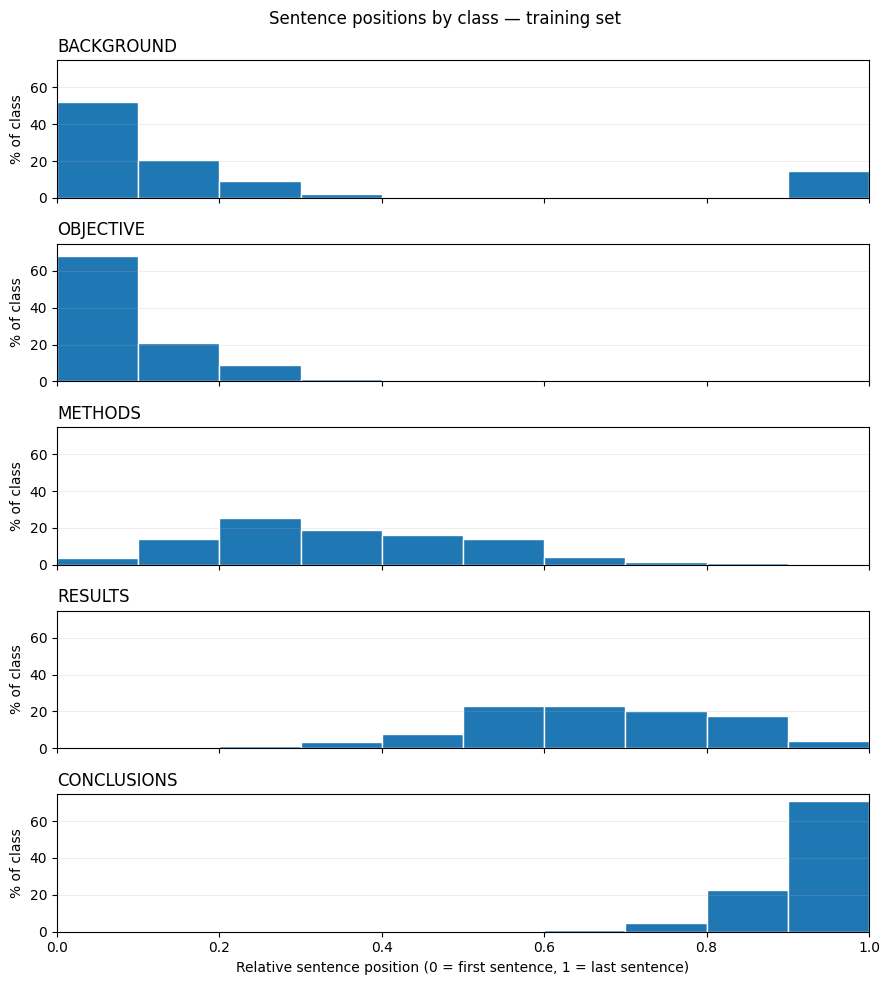

In [92]:
import numpy as np
import matplotlib.pyplot as plt

# Calculate relative position using training data only.
position_analysis = train_df.copy()

abstract_sizes = (
    position_analysis.groupby("abstract_id")["sentence"]
    .transform("size")
)

position_analysis["relative_position"] = (
    position_analysis["sentence_number"]
    / (abstract_sizes - 1).clip(lower=1)
)

# Use the same position bins and axes for every class.
label_order = [
    "BACKGROUND", "OBJECTIVE", "METHODS", "RESULTS", "CONCLUSIONS"
]
bins = np.linspace(0, 1, 11)

fig, axes = plt.subplots(
    len(label_order), 1,
    figsize=(9, 10),
    sharex=True,
    sharey=True,
)

for ax, label in zip(axes, label_order):
    positions = position_analysis.loc[
        position_analysis["label"] == label,
        "relative_position",
    ].to_numpy()

    # Each sentence contributes an equal share of its class's total.
    weights = np.full(len(positions), 100 / len(positions))

    ax.hist(
        positions,
        bins=bins,
        weights=weights,
        edgecolor="white",
    )
    ax.set_title(label, loc="left")
    ax.set_ylabel("% of class")
    ax.grid(axis="y", alpha=0.2)

axes[-1].set_xlabel(
    "Relative sentence position (0 = first sentence, 1 = last sentence)"
)
axes[-1].set_xlim(0, 1)

fig.suptitle("Sentence positions by class — training set")
fig.tight_layout()
plt.show()

In [93]:
# Inspect BACKGROUND-labelled training sentences near the end of abstracts.
late_background = position_analysis.loc[
    (position_analysis["label"] == "BACKGROUND")
    & (position_analysis["relative_position"] >= 0.9)
]

background_count = position_analysis["label"].eq("BACKGROUND").sum()

print(f"Late BACKGROUND sentences: {len(late_background):,}")
print(f"Percentage of BACKGROUND: {len(late_background) / background_count:.2%}")

for _, row in late_background.sample(
    n=min(10, len(late_background)),
    random_state=42,
).iterrows():
    print(
        f"\nAbstract: {row['abstract_id']} | "
        f"Position: {row['relative_position']:.3f}"
    )
    print(row["sentence"])

Late BACKGROUND sentences: 3,173
Percentage of BACKGROUND: 14.60%

Abstract: 24484541 | Position: 1.000
ClinicalTrials.gov NCT01849445 .

Abstract: 24885637 | Position: 1.000
The trial is registered at the Dutch Trial Register : NTR3413 .

Abstract: 25182269 | Position: 1.000
This study is registered with ClinicalTrials.gov , number NCT01731717 ( date of registration : 24 June 2013 ) .

Abstract: 25384017 | Position: 1.000
clinicaltrials.gov Identifier : NCT01979302 .

Abstract: 24862342 | Position: 1.000
clinicaltrials.gov Identifier : NCT01247064 .

Abstract: 25027459 | Position: 1.000
Current Controlled Trials ISRCTN 17807356 .

Abstract: 25564143 | Position: 1.000
ISRCTN91327214 .

Abstract: 25660356 | Position: 1.000
AstraZeneca .

Abstract: 25898052 | Position: 1.000
isrctn.org Identifier : ISRCTN76104595 .

Abstract: 25472808 | Position: 1.000
EudraCT Identifier : 2014-001499-73 ; 31 July 2014 .


For your analysis, try writing two sentences: one reporting the 14.60% observation, and one explaining what the sampled content suggests, making the distinction between the full count and the sample explicit.

From the normalized histrogram we can interestingly observe that a noticeable portion (14.60% of BACKGROUND-labelled training sentences) of BACKGROUND resisdes in the end of abstract. Upon examining 10 samples, we see that 9/10 are Trial-registration information. So, some BACKGROUND-labelled sentences occur near the end of abstracts as well, making the sentcne position only not being able to distniguish, closer examination of sentecne content is also needed.

In [94]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Use only relative position as the input feature.
# Double brackets preserve the required shape: [number_of_sentences, 1].
X_train_position_only = train_position_df[["relative_position"]]
X_validation_position_only = validation_position_df[["relative_position"]]

y_train_position_only = train_position_df["label"]
y_validation_position_only = validation_position_df["label"]

# Fit on training data only.
position_only_model = LogisticRegression(max_iter=1000)
position_only_model.fit(
    X_train_position_only,
    y_train_position_only,
)

# Predict validation labels without using sentence text.
position_only_predictions = position_only_model.predict(
    X_validation_position_only
)

position_only_accuracy = accuracy_score(
    y_validation_position_only,
    position_only_predictions,
)
position_only_macro_f1 = f1_score(
    y_validation_position_only,
    position_only_predictions,
    average="macro",
)

print(f"Position-only validation accuracy: {position_only_accuracy:.2%}")
print(f"Position-only validation macro-F1: {position_only_macro_f1:.4f}")

print(classification_report(
    y_validation_position_only,
    position_only_predictions,
    labels=label_order,
    digits=3,
    zero_division=0,
))

Position-only validation accuracy: 68.78%
Position-only validation macro-F1: 0.5561
              precision    recall  f1-score   support

  BACKGROUND      0.000     0.000     0.000      3449
   OBJECTIVE      0.512     0.544     0.527      2376
     METHODS      0.648     0.859     0.739      9964
     RESULTS      0.755     0.755     0.755      9841
 CONCLUSIONS      0.754     0.765     0.759      4582

    accuracy                          0.688     30212
   macro avg      0.534     0.584     0.556     30212
weighted avg      0.614     0.688     0.646     30212



In [95]:
# Count how often the position-only model predicts each class.
position_only_prediction_counts = (
    pd.Series(position_only_predictions)
    .value_counts()
    .reindex(label_order, fill_value=0)
)

print(position_only_prediction_counts)

BACKGROUND         0
OBJECTIVE       2527
METHODS        13196
RESULTS         9841
CONCLUSIONS     4648
Name: count, dtype: int64


In [96]:
# Add the position-only baseline using calculated validation metrics.
position_only_result = pd.DataFrame([{
    "Model": "Position-only logistic regression",
    "Initialization": "Fit on training data",
    "Features": "Relative position",
    "Training loss": "Logistic loss + L2 penalty",
    "Selected epoch": pd.NA,
    "Epoch unit": "N/A",
    "Validation accuracy (%)": position_only_accuracy * 100,
    "Validation macro-F1": position_only_macro_f1,
}])

# Remove any previous entry for this experiment to avoid duplicate rows.
experiment_summary = experiment_summary.loc[
    experiment_summary["Model"] != position_only_result.loc[0, "Model"]
].copy()

experiment_summary = pd.concat(
    [experiment_summary, position_only_result],
    ignore_index=True,
)
experiment_summary["Selected epoch"] = (
    experiment_summary["Selected epoch"].astype("Int64")
)

# Save the updated comparison beside your checkpoints folder.
results_dir = checkpoint_dir.parent / "results"
results_dir.mkdir(parents=True, exist_ok=True)

summary_path = results_dir / "validation_experiment_summary.csv"
experiment_summary.to_csv(summary_path, index=False)

display(experiment_summary.style.format({
    "Validation accuracy (%)": "{:.2f}",
    "Validation macro-F1": "{:.4f}",
}, na_rep="N/A"))

print(f"Saved to: {summary_path}")

/tmp/ipykernel_681/1125989581.py:18: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  experiment_summary = pd.concat(


,Model,Initialization,Features,Training loss,Selected epoch,Epoch unit,Validation accuracy (%),Validation macro-F1
0,Majority baseline,Training majority class,None,N/A,N/A,N/A,32.98,0.0992
1,TF-IDF + logistic regression,Fit on training data,TF-IDF,Logistic loss + L2 penalty,N/A,N/A,80.92,0.7438
2,Mean embedding classifier,Random,Mean token embeddings,Cross-entropy,4,training,80.71,0.7426
3,CNN,Random,CNN text features,Cross-entropy,3,training,81.11,0.7464
4,Class-weighted CNN,Random,CNN text features,Class-weighted cross-entropy,3,training,79.42,0.7360
5,CNN + position,Random,CNN text features + relative position,Cross-entropy,4,training,85.58,0.8018
6,"CNN + position, fine-tuned",Original CNN best checkpoint,CNN text features + relative position,Cross-entropy,2,additional fine-tuning,84.28,0.7882
7,Position-only logistic regression,Fit on training data,Relative position,Logistic loss + L2 penalty,N/A,N/A,68.78,0.5561


Saved to: /content/drive/MyDrive/Portfolio_Project/Abstract_Classifier/results/validation_experiment_summary.csv


We see that position alone achieved 68.78% accuracy, compared with 32.98% for the majority baseline. Position carries substantial predictive information, but the lower macro-F1 of 0.5561 exposes its uneven performance across classes.

The position-only model never predicts BACKGROUND. Its zero recall means all 3,449 actual BACKGROUND sentences were assigned another label.

In [97]:
import random
import numpy as np
import torch
from torch.utils.data import DataLoader


# Use the same seed list for both model configurations.
experiment_seeds = [42, 123, 2026]
num_epochs_per_run = 5



# Demonstrate reproducible random initialization.
set_random_seed(experiment_seeds[1])
first_draw = torch.rand(3)

set_random_seed(experiment_seeds[1])
second_draw = torch.rand(3)

print("First draw: ", first_draw)
print("Second draw:", second_draw)
print("Identical:", torch.equal(first_draw, second_draw))

First draw:  tensor([0.2961, 0.5166, 0.2517])
Second draw: tensor([0.2961, 0.5166, 0.2517])
Identical: True


In [98]:
import random
import numpy as np
import pandas as pd
import torch
from torch import nn


# Keep experiment settings fixed across seeds.
seed = experiment_seeds[2]
learning_rate = 0.001

run_config = {
    "seed": seed,
    "embedding_dim": cnn_model.embedding.embedding_dim,
    "num_filters": cnn_model.conv.out_channels,
    "kernel_size": 3,
    "padding": 1,
    "batch_size": train_loader.batch_size,
    "drop_last": train_loader.drop_last,
    "learning_rate": learning_rate,
    "tokenizer": "lowercase_then_whitespace_split",
}

# Separate files from the earlier best-only experiment.
seed_run_dir = checkpoint_dir / "random_seed_experiments_resumable"
seed_run_dir.mkdir(parents=True, exist_ok=True)

seed_best_path = seed_run_dir / f"cnn_seed_{seed}_best.pt"
seed_latest_path = seed_run_dir / f"cnn_seed_{seed}_latest.pt"
seed_history_path = seed_run_dir / f"cnn_seed_{seed}_history.csv"

set_random_seed(seed)
seeded_train_loader = make_seeded_train_loader(train_loader, seed)

seeded_cnn = CNNAbstractClassifier(
    vocab_size=len(vocab),
    embedding_dim=run_config["embedding_dim"],
    num_filters=run_config["num_filters"],
    num_classes=len(label_to_id),
    pad_id=vocab["<PAD>"],
)

seeded_optimizer = torch.optim.Adam(
    seeded_cnn.parameters(),
    lr=learning_rate,
)
seeded_loss_fn = nn.CrossEntropyLoss()

start_epoch = 1
seed_best_loss = float("inf")
seed_best_epoch = None
seed_history = []


# Resume from the LATEST state, not the best validation state.
if seed_latest_path.exists():
    latest_checkpoint = torch.load(
        seed_latest_path,
        map_location="cpu",
        weights_only=True,
    )

    # Prevent accidentally resuming a different experiment.
    assert latest_checkpoint["config"] == run_config, (
        "Settings differ from the saved run. Use a new folder "
        "for a different experiment."
    )
    assert latest_checkpoint["vocab"] == vocab
    assert latest_checkpoint["label_to_id"] == label_to_id

    seeded_cnn.load_state_dict(
        latest_checkpoint["model_state_dict"]
    )
    seeded_optimizer.load_state_dict(
        latest_checkpoint["optimizer_state_dict"]
    )

    start_epoch = latest_checkpoint["epochs_completed"] + 1
    seed_best_loss = latest_checkpoint["best_validation_loss"]
    seed_best_epoch = latest_checkpoint["best_epoch"]
    seed_history = latest_checkpoint["history"]

    # Restore randomness AFTER constructing/loading model and optimizer.
    restore_random_states(
        latest_checkpoint["random_states"],
        seeded_train_loader,
    )

    print(f"Resuming seed {seed} from epoch {start_epoch}.")
else:
    if start_epoch > num_epochs_per_run:
        print(
            f"Seed {seed}: all {num_epochs_per_run} epochs are complete. "
            "Skipping training and loading the best model."
        )
    else:
        print(f"Resuming seed {seed} from epoch {start_epoch}.")


for epoch in range(start_epoch, num_epochs_per_run + 1):
    train_loss, train_accuracy = run_seeded_cnn_epoch(
        seeded_cnn,
        seeded_train_loader,
        seeded_loss_fn,
        optimizer=seeded_optimizer,
    )

    val_loss, val_accuracy = run_seeded_cnn_epoch(
        seeded_cnn,
        validation_loader,
        seeded_loss_fn,
    )

    seed_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
    })

    improved = val_loss < seed_best_loss
    if improved:
        seed_best_loss = val_loss
        seed_best_epoch = epoch

    checkpoint = {
        "model_state_dict": seeded_cnn.state_dict(),
        "optimizer_state_dict": seeded_optimizer.state_dict(),
        "epochs_completed": epoch,
        "best_epoch": seed_best_epoch,
        "best_validation_loss": seed_best_loss,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
        "history": seed_history,
        "random_states": capture_random_states(seeded_train_loader),
        "config": run_config,
        "vocab": vocab,
        "label_to_id": label_to_id,
        "pad_id": vocab["<PAD>"],
    }

    # Best: evaluation. Latest: continuing training.
    if improved:
        save_checkpoint(checkpoint, seed_best_path)

    save_checkpoint(checkpoint, seed_latest_path)

    # Save the learning curve every epoch as well.
    pd.DataFrame(seed_history).to_csv(
        seed_history_path,
        index=False,
    )

    print(
        f"Seed {seed} | Epoch {epoch} | "
        f"Train loss: {train_loss:.4f}, accuracy: {train_accuracy:.2%} | "
        f"Validation loss: {val_loss:.4f}, accuracy: {val_accuracy:.2%}"
        " | Latest saved"
        + (" | Best saved" if improved else "")
    )


# Load the best model for subsequent evaluation.
best_seed_checkpoint = torch.load(
    seed_best_path,
    map_location="cpu",
    weights_only=True,
)

seeded_cnn.load_state_dict(
    best_seed_checkpoint["model_state_dict"]
)
seeded_cnn.eval()

print(
    f"\nSelected epoch: {best_seed_checkpoint['best_epoch']}\n"
    f"Best validation loss: "
    f"{best_seed_checkpoint['validation_loss']:.4f}\n"
    f"Best validation accuracy: "
    f"{best_seed_checkpoint['validation_accuracy']:.2%}"
)
print(f"Resume checkpoint: {seed_latest_path}")

Resuming seed 2026 from epoch 6.

Selected epoch: 3
Best validation loss: 0.5283
Best validation accuracy: 80.50%
Resume checkpoint: /content/drive/MyDrive/Portfolio_Project/Abstract_Classifier/checkpoints/random_seed_experiments_resumable/cnn_seed_2026_latest.pt


In [99]:
# Recover all completed epochs from the saved checkpoint.
saved_run = torch.load(
    seed_latest_path,
    map_location="cpu",
    weights_only=True,
)

saved_history = pd.DataFrame(saved_run["history"])

display(saved_history.style.format({
    "train_loss": "{:.4f}",
    "train_accuracy": "{:.2%}",
    "validation_loss": "{:.4f}",
    "validation_accuracy": "{:.2%}",
}))

,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy
0,1,0.7070,73.34%,0.5761,78.42%
1,2,0.5332,80.49%,0.5415,79.99%
2,3,0.4676,83.03%,0.5283,80.50%
3,4,0.4151,85.05%,0.5291,80.97%
4,5,0.3664,86.94%,0.5406,80.97%


In [100]:
#load seed 42 specifically, hard coded

from sklearn.metrics import accuracy_score, f1_score

# Load seed 42's earlier best-only checkpoint.
seed42_path = (
    checkpoint_dir
    / "random_seed_experiments"
    / "cnn_seed_42_best.pt"
)

seed42_checkpoint = torch.load(
    seed42_path,
    map_location="cpu",
    weights_only=True,
)

# Confirm that token IDs and label IDs have the same meanings.
assert seed42_checkpoint["vocab"] == vocab
assert seed42_checkpoint["label_to_id"] == label_to_id

seed42_model = CNNAbstractClassifier(
    vocab_size=len(vocab),
    embedding_dim=seed42_checkpoint["embedding_dim"],
    num_filters=seed42_checkpoint["num_filters"],
    num_classes=len(label_to_id),
    pad_id=seed42_checkpoint["pad_id"],
)
seed42_model.load_state_dict(seed42_checkpoint["model_state_dict"])
seed42_model.eval()

seed42_actual = []
seed42_predictions = []

with torch.no_grad():
    for token_ids, labels in validation_loader:
        predictions = seed42_model(token_ids).argmax(dim=1)
        seed42_actual.extend(labels.tolist())
        seed42_predictions.extend(predictions.tolist())

seed42_result = pd.DataFrame([{
    "Model": "CNN",
    "Seed": seed42_checkpoint["seed"],
    "Selected epoch": seed42_checkpoint["selected_epoch"],
    "Validation accuracy (%)": (
        accuracy_score(seed42_actual, seed42_predictions) * 100
    ),
    "Validation macro-F1": f1_score(
        seed42_actual,
        seed42_predictions,
        labels=sorted(id_to_label),
        average="macro",
        zero_division=0,
    ),
}])

# Store all three seeds' result files in the same directory.
seed_results_dir = checkpoint_dir / "random_seed_experiments_resumable"
seed_results_dir.mkdir(parents=True, exist_ok=True)

seed42_result.to_csv(
    seed_results_dir / "cnn_seed_42_results.csv",
    index=False,
)

# Read the calculated results for every planned seed.
cnn_seed_results = pd.concat(
    [
        pd.read_csv(seed_results_dir / f"cnn_seed_{seed}_results.csv")
        for seed in experiment_seeds
    ],
    ignore_index=True,
).sort_values("Seed")

display(cnn_seed_results)

# Summarize performance across seeds.
cnn_seed_summary = (
    cnn_seed_results.groupby("Model")
    .agg(
        Runs=("Seed", "count"),
        Accuracy_mean=("Validation accuracy (%)", "mean"),
        Accuracy_std=("Validation accuracy (%)", "std"),
        Macro_F1_mean=("Validation macro-F1", "mean"),
        Macro_F1_std=("Validation macro-F1", "std"),
    )
    .reset_index()
)

display(cnn_seed_summary)

cnn_seed_results.to_csv(
    seed_results_dir / "cnn_all_seed_results.csv",
    index=False,
)
cnn_seed_summary.to_csv(
    seed_results_dir / "cnn_seed_summary.csv",
    index=False,
)

,Model,Seed,Selected epoch,Validation accuracy (%),Validation macro-F1
0,CNN,42,4,81.159804,0.747099
1,CNN,123,3,80.842050,0.743493
2,CNN,2026,3,80.497815,0.738313


,Model,Runs,Accuracy_mean,Accuracy_std,Macro_F1_mean,Macro_F1_std
0,CNN,3,80.833223,0.331083,0.742968,0.004416


Text only original CNN

| Metric | Mean ± standard deviation |
|---|---:|
| Validation accuracy | **80.83% ± 0.33 percentage points** |
| Validation macro-F1 | **0.7430 ± 0.0044** |


The results are fairly consistent across these three runs. This measures variation from initialization and batch order on the same validation set; it is not a confidence interval for performance on new data.

In [101]:

from sklearn.metrics import accuracy_score, f1_score

#seed = experiment_seeds[0]  # Start with 42; later use [1] and [2].
learning_rate = 0.001



# Separate files from the earlier best-only experiment.

# Keep function definitions outside the loop:
# run_seeded_position_epoch, set_random_seed,
# make_seeded_train_loader, checkpoint helpers, etc.

seed_run_dir = checkpoint_dir / "random_seed_experiments_resumable"
seed_run_dir.mkdir(parents=True, exist_ok=True)

for seed in experiment_seeds:
    print(f"\n===== CNN + position | Seed {seed} =====")

    # 1. Build run_config here so it contains the current seed.


    # Match the text-only CNN's dimensions for the comparison.
    run_config = {
        "model": "CNN + position",
        "seed": seed,
        "embedding_dim": cnn_model.embedding.embedding_dim,
        "num_filters": cnn_model.conv.out_channels,
        "kernel_size": 3,
        "padding": 1,
        "batch_size": position_train_loader.batch_size,
        "drop_last": position_train_loader.drop_last,
        "learning_rate": learning_rate,
        "tokenizer": "lowercase_then_whitespace_split",
        "position_feature": "sentence_number / max(total_sentences - 1, 1)",
    }


    # 2. Create seed-specific best/latest/history paths.

    seed_best_path = seed_run_dir / f"cnn_position_seed_{seed}_best.pt"
    seed_latest_path = seed_run_dir / f"cnn_position_seed_{seed}_latest.pt"
    seed_history_path = seed_run_dir / f"cnn_position_seed_{seed}_history.csv"

    # 3. Set the seed and create the training loader.
    set_random_seed(seed)
    seeded_position_train_loader = make_seeded_train_loader(
        position_train_loader, seed
    )

    # 4. Create a fresh PositionCNN and optimizer.

    seeded_position_cnn = PositionCNN(
        vocab_size=len(vocab),
        embedding_dim=run_config["embedding_dim"],
        num_filters=run_config["num_filters"],
        num_classes=len(label_to_id),
        pad_id=vocab["<PAD>"],
    )


    seeded_position_optimizer = torch.optim.Adam(
        seeded_position_cnn.parameters(),
        lr=learning_rate,
    )
    seeded_position_loss_fn = nn.CrossEntropyLoss()

    # 5. Reset this run's tracking variables.
    start_epoch = 1
    seed_best_loss = float("inf")
    seed_best_epoch = None
    seed_history = []

    # 6. Load this seed's latest checkpoint if it exists.


    # Resume from the LATEST state, not the best validation state.
    if seed_latest_path.exists():
        latest_checkpoint = torch.load(
            seed_latest_path,
            map_location="cpu",
            weights_only=True,
        )

        # Prevent accidentally resuming a different experiment.
        assert latest_checkpoint["config"] == run_config, (
            "Settings differ from the saved run. Use a new folder "
            "for a different experiment."
        )
        assert latest_checkpoint["vocab"] == vocab
        assert latest_checkpoint["label_to_id"] == label_to_id

        seeded_position_cnn.load_state_dict(
            latest_checkpoint["model_state_dict"]
        )
        seeded_position_optimizer.load_state_dict(
            latest_checkpoint["optimizer_state_dict"]
        )

        start_epoch = latest_checkpoint["epochs_completed"] + 1
        seed_best_loss = latest_checkpoint["best_validation_loss"]
        seed_best_epoch = latest_checkpoint["best_epoch"]
        seed_history = latest_checkpoint["history"]

        # Restore randomness AFTER constructing/loading model and optimizer.
        restore_random_states(
            latest_checkpoint["random_states"],
            seeded_position_train_loader,
        )

        if start_epoch > num_epochs_per_run:
            print(
                f"Seed {seed}: all {num_epochs_per_run} epochs are complete. "
                "Skipping training and loading the best model."
            )
        else:
            print(f"Resuming seed {seed} from epoch {start_epoch}.")
    else:
        print(f"Starting a fresh position-model run for seed {seed}.")

    # 7. Train any remaining epochs.
    for epoch in range(start_epoch, num_epochs_per_run + 1):
        train_loss, train_accuracy = run_seeded_position_epoch(
            seeded_position_cnn,
            seeded_position_train_loader,
            seeded_position_loss_fn,
            optimizer=seeded_position_optimizer,
        )

        val_loss, val_accuracy = run_seeded_position_epoch(
            seeded_position_cnn,
            position_validation_loader,
            seeded_position_loss_fn,
        )

        seed_history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "validation_loss": val_loss,
            "validation_accuracy": val_accuracy,
        })

        improved = val_loss < seed_best_loss
        if improved:
            seed_best_loss = val_loss
            seed_best_epoch = epoch

        checkpoint = {
            "model_state_dict": seeded_position_cnn.state_dict(),
            "optimizer_state_dict": seeded_position_optimizer.state_dict(),
            "epochs_completed": epoch,
            "best_epoch": seed_best_epoch,
            "best_validation_loss": seed_best_loss,
            "validation_loss": val_loss,
            "validation_accuracy": val_accuracy,
            "history": seed_history,
            "random_states": capture_random_states(seeded_position_train_loader),
            "config": run_config,
            "vocab": vocab,
            "label_to_id": label_to_id,
            "pad_id": vocab["<PAD>"],
        }

        # Best: evaluation. Latest: continuing training.
        if improved:
            save_checkpoint(checkpoint, seed_best_path)

        save_checkpoint(checkpoint, seed_latest_path)

        # Save the learning curve every epoch as well.
        pd.DataFrame(seed_history).to_csv(
            seed_history_path,
            index=False,
        )

        print(
            f"Seed {seed} | Epoch {epoch} | "
            f"Train loss: {train_loss:.4f}, accuracy: {train_accuracy:.2%} | "
            f"Validation loss: {val_loss:.4f}, accuracy: {val_accuracy:.2%}"
            " | Latest saved"
            + (" | Best saved" if improved else "")
        )

    # 8. Restore this seed's best model.
    # Calculate and save its accuracy and macro-F1 here.

    # Load the best model for subsequent evaluation.
    best_seed_checkpoint = torch.load(
        seed_best_path,
        map_location="cpu",
        weights_only=True,
    )

    seeded_position_cnn.load_state_dict(
        best_seed_checkpoint["model_state_dict"]
    )
    seeded_position_cnn.eval()

    print(
        f"\nSelected epoch: {best_seed_checkpoint['best_epoch']}\n"
        f"Best validation loss: "
        f"{best_seed_checkpoint['validation_loss']:.4f}\n"
        f"Best validation accuracy: "
        f"{best_seed_checkpoint['validation_accuracy']:.2%}"
    )
    print(f"Resume checkpoint: {seed_latest_path}")


    # Evaluate and save this seed's best model before moving to the next seed.
    position_seed_actual = []
    position_seed_predictions = []

    with torch.no_grad():
        for token_ids, positions, labels in position_validation_loader:
            predictions = seeded_position_cnn(
                token_ids, positions
            ).argmax(dim=1)

            position_seed_actual.extend(labels.tolist())
            position_seed_predictions.extend(predictions.tolist())

    position_seed_result = pd.DataFrame([{
        "Model": "CNN + position",
        "Seed": seed,
        "Selected epoch": best_seed_checkpoint["best_epoch"],
        "Validation accuracy (%)": accuracy_score(
            position_seed_actual,
            position_seed_predictions,
        ) * 100,
        "Validation macro-F1": f1_score(
            position_seed_actual,
            position_seed_predictions,
            labels=sorted(id_to_label),
            average="macro",
            zero_division=0,
        ),
    }])

    position_seed_result.to_csv(
        seed_run_dir / f"cnn_position_seed_{seed}_results.csv",
        index=False,
    )

    display(position_seed_result)






===== CNN + position | Seed 42 =====
Seed 42: all 5 epochs are complete. Skipping training and loading the best model.

Selected epoch: 4
Best validation loss: 0.3921
Best validation accuracy: 85.58%
Resume checkpoint: /content/drive/MyDrive/Portfolio_Project/Abstract_Classifier/checkpoints/random_seed_experiments_resumable/cnn_position_seed_42_latest.pt


,Model,Seed,Selected epoch,Validation accuracy (%),Validation macro-F1
0,CNN + position,42,4,85.581888,0.801845



===== CNN + position | Seed 123 =====
Seed 123: all 5 epochs are complete. Skipping training and loading the best model.

Selected epoch: 4
Best validation loss: 0.3978
Best validation accuracy: 85.30%
Resume checkpoint: /content/drive/MyDrive/Portfolio_Project/Abstract_Classifier/checkpoints/random_seed_experiments_resumable/cnn_position_seed_123_latest.pt


,Model,Seed,Selected epoch,Validation accuracy (%),Validation macro-F1
0,CNN + position,123,4,85.297233,0.793787



===== CNN + position | Seed 2026 =====
Seed 2026: all 5 epochs are complete. Skipping training and loading the best model.

Selected epoch: 4
Best validation loss: 0.3929
Best validation accuracy: 85.52%
Resume checkpoint: /content/drive/MyDrive/Portfolio_Project/Abstract_Classifier/checkpoints/random_seed_experiments_resumable/cnn_position_seed_2026_latest.pt


,Model,Seed,Selected epoch,Validation accuracy (%),Validation macro-F1
0,CNN + position,2026,4,85.522309,0.803011


CNN + position outperformed the text-only CNN in both metrics for every seed. That supports the improvement being consistent across these three runs.

In [102]:
import pandas as pd

seed_results_dir = checkpoint_dir / "random_seed_experiments_resumable"

# Load one result file per model and seed.
result_frames = []

for prefix in ["cnn", "cnn_position"]:
    for seed in experiment_seeds:
        result_path = seed_results_dir / f"{prefix}_seed_{seed}_results.csv"
        result_frames.append(pd.read_csv(result_path))

all_seed_results = pd.concat(result_frames, ignore_index=True)

# Verify that each model has exactly one result for every planned seed.
assert not all_seed_results.duplicated(["Model", "Seed"]).any()

for model_name, group in all_seed_results.groupby("Model"):
    assert set(group["Seed"]) == set(experiment_seeds), (
        f"Missing or unexpected seeds for {model_name}"
    )

# Calculate means and sample standard deviations across runs.
seed_comparison = (
    all_seed_results.groupby("Model", sort=False)
    .agg(
        Runs=("Seed", "count"),
        Accuracy_mean=("Validation accuracy (%)", "mean"),
        Accuracy_std=("Validation accuracy (%)", "std"),
        Macro_F1_mean=("Validation macro-F1", "mean"),
        Macro_F1_std=("Validation macro-F1", "std"),
    )
    .reset_index()
)

display(seed_comparison.style.format({
    "Accuracy_mean": "{:.2f}",
    "Accuracy_std": "{:.2f}",
    "Macro_F1_mean": "{:.4f}",
    "Macro_F1_std": "{:.4f}",
}))

# Compare the two models separately for each matching seed.
accuracy_by_seed = all_seed_results.pivot(
    index="Seed", columns="Model", values="Validation accuracy (%)"
)
f1_by_seed = all_seed_results.pivot(
    index="Seed", columns="Model", values="Validation macro-F1"
)

seed_improvements = pd.DataFrame({
    "Accuracy gain (percentage points)": (
        accuracy_by_seed["CNN + position"] - accuracy_by_seed["CNN"]
    ),
    "Macro-F1 gain": (
        f1_by_seed["CNN + position"] - f1_by_seed["CNN"]
    ),
}).reset_index()

display(seed_improvements.style.format({
    "Accuracy gain (percentage points)": "{:.2f}",
    "Macro-F1 gain": "{:.4f}",
}))

# Preserve full-precision results.
all_seed_results.to_csv(
    seed_results_dir / "all_seed_results.csv", index=False
)
seed_comparison.to_csv(
    seed_results_dir / "model_seed_comparison.csv", index=False
)
seed_improvements.to_csv(
    seed_results_dir / "position_gain_by_seed.csv", index=False
)

,Model,Runs,Accuracy_mean,Accuracy_std,Macro_F1_mean,Macro_F1_std
0,CNN,3,80.83,0.33,0.7430,0.0044
1,CNN + position,3,85.47,0.15,0.7995,0.0050


,Seed,Accuracy gain (percentage points),Macro-F1 gain
0,42,4.42,0.0547
1,123,4.46,0.0503
2,2026,5.02,0.0647


In [103]:
import json
import pandas as pd
import torch

# Select the final checkpoint using validation results only.
candidate_dir = checkpoint_dir / "random_seed_experiments_resumable"
selection_path = candidate_dir / "final_model_selection.json"

if selection_path.exists():
    # Reuse the recorded decision on later notebook runs.
    with selection_path.open(encoding="utf-8") as file:
        final_selection = json.load(file)

    print("Loaded the previously recorded final-model selection.")

else:
    candidates = []

    for seed in experiment_seeds:
        path = candidate_dir / f"cnn_position_seed_{seed}_best.pt"
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=True,
        )

        candidates.append({
            "seed": seed,
            "selected_epoch": checkpoint["best_epoch"],
            "validation_loss": checkpoint["validation_loss"],
            "checkpoint_filename": path.name,
        })

    # Lowest validation loss wins; smaller seed breaks an exact tie.
    selected = min(
        candidates,
        key=lambda row: (row["validation_loss"], row["seed"]),
    )

    final_selection = {
        "model": "CNN + position",
        "configuration_rule": (
            "Highest mean validation accuracy and macro-F1 "
            "among the two configurations evaluated across three seeds."
        ),
        "checkpoint_rule": (
            "Lowest validation loss among the configuration's "
            "three best checkpoints; smaller seed breaks an exact tie."
        ),
        **selected,
    }

    with selection_path.open("w", encoding="utf-8") as file:
        json.dump(final_selection, file, indent=2)

    print("Recorded the final-model selection before test evaluation.")

final_checkpoint_path = (
    candidate_dir / final_selection["checkpoint_filename"]
)

display(pd.DataFrame([{
    "Model": final_selection["model"],
    "Seed": final_selection["seed"],
    "Selected epoch": final_selection["selected_epoch"],
    "Validation loss": final_selection["validation_loss"],
}]))

print(f"Selected checkpoint: {final_checkpoint_path}")
print(f"Selection record: {selection_path}")

Loaded the previously recorded final-model selection.


,Model,Seed,Selected epoch,Validation loss
0,CNN + position,42,4,0.392052


Selected checkpoint: /content/drive/MyDrive/Portfolio_Project/Abstract_Classifier/checkpoints/random_seed_experiments_resumable/cnn_position_seed_42_best.pt
Selection record: /content/drive/MyDrive/Portfolio_Project/Abstract_Classifier/checkpoints/random_seed_experiments_resumable/final_model_selection.json


In [104]:
import json
import pandas as pd
import torch

from torch import nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# 1. Load the model selection already recorded using validation data.
candidate_dir = checkpoint_dir / "random_seed_experiments_resumable"

with (candidate_dir / "final_model_selection.json").open(
    encoding="utf-8"
) as file:
    final_selection = json.load(file)

final_checkpoint_path = (
    candidate_dir / final_selection["checkpoint_filename"]
)

final_checkpoint = torch.load(
    final_checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

final_vocab = final_checkpoint["vocab"]
final_label_to_id = final_checkpoint["label_to_id"]
final_config = final_checkpoint["config"]

assert final_config["tokenizer"] == "lowercase_then_whitespace_split"

final_label_ids = sorted(final_label_to_id.values())
final_id_to_label = {
    index: label for label, index in final_label_to_id.items()
}
final_label_names = [
    final_id_to_label[index] for index in final_label_ids
]

# 2. Reconstruct the selected model and restore its trained weights.
final_model = PositionCNN(
    vocab_size=len(final_vocab),
    embedding_dim=final_config["embedding_dim"],
    num_filters=final_config["num_filters"],
    num_classes=len(final_label_to_id),
    pad_id=final_checkpoint["pad_id"],
)

final_model.load_state_dict(final_checkpoint["model_state_dict"])
final_model.eval()

# 3. Compute position from each complete test abstract.
# This uses sentence order and abstract length, not the labels.
final_test_df = test_df.copy().reset_index(drop=True)

abstract_sizes = (
    final_test_df.groupby("abstract_id")["sentence"].transform("size")
)
final_test_df["relative_position"] = (
    final_test_df["sentence_number"]
    / (abstract_sizes - 1).clip(lower=1)
)

# Encode using the SAVED training vocabulary and label mapping.
test_examples = []

for row in final_test_df.itertuples(index=False):
    token_ids = [
        final_vocab.get(token, final_vocab["<UNK>"])
        for token in row.sentence.lower().split()
    ]
    assert token_ids, "An empty test sentence needs investigation."

    test_examples.append((
        torch.tensor(token_ids, dtype=torch.long),
        torch.tensor(row.relative_position, dtype=torch.float32),
        torch.tensor(final_label_to_id[row.label], dtype=torch.long),
    ))


def collate_final_test(batch):
    """Pad sentence tokens and stack positions and reference labels."""
    tokens, positions, labels = zip(*batch)

    return (
        pad_sequence(
            tokens,
            batch_first=True,
            padding_value=final_checkpoint["pad_id"],
        ),
        torch.stack(positions),
        torch.stack(labels),
    )


final_test_loader = DataLoader(
    test_examples,
    batch_size=final_config["batch_size"],
    shuffle=False,
    drop_last=False,
    collate_fn=collate_final_test,
    num_workers=0,
)

# 4. Predict without updating any model parameters.
test_actual = []
test_predictions = []
test_loss_sum = 0.0
test_loss_fn = nn.CrossEntropyLoss(reduction="sum")

with torch.no_grad():
    for token_ids, positions, labels in final_test_loader:
        logits = final_model(token_ids, positions)

        test_loss_sum += test_loss_fn(logits, labels).item()
        test_actual.extend(labels.tolist())
        test_predictions.extend(logits.argmax(dim=1).tolist())

test_metrics = {
    "Model": final_selection["model"],
    "Seed": final_selection["seed"],
    "Selected epoch": final_selection["selected_epoch"],
    "Test loss": test_loss_sum / len(test_actual),
    "Test accuracy (%)": (
        accuracy_score(test_actual, test_predictions) * 100
    ),
    "Test macro-F1": f1_score(
        test_actual,
        test_predictions,
        labels=final_label_ids,
        average="macro",
        zero_division=0,
    ),
}

test_report = classification_report(
    test_actual,
    test_predictions,
    labels=final_label_ids,
    target_names=final_label_names,
    output_dict=True,
    zero_division=0,
)

test_confusion_df = pd.DataFrame(
    confusion_matrix(
        test_actual,
        test_predictions,
        labels=final_label_ids,
    ),
    index=pd.Index(final_label_names, name="Actual"),
    columns=pd.Index(final_label_names, name="Predicted"),
)

display(pd.DataFrame([test_metrics]))

print(classification_report(
    test_actual,
    test_predictions,
    labels=final_label_ids,
    target_names=final_label_names,
    digits=3,
    zero_division=0,
))

display(test_confusion_df)

# 5. Save results so they survive a runtime disconnection.
final_results_dir = checkpoint_dir.parent / "results" / "final_test"
final_results_dir.mkdir(parents=True, exist_ok=True)

pd.DataFrame([test_metrics]).to_csv(
    final_results_dir / "test_metrics.csv",
    index=False,
)
pd.DataFrame(test_report).T.to_csv(
    final_results_dir / "test_classification_report.csv",
)
test_confusion_df.to_csv(
    final_results_dir / "test_confusion_matrix.csv",
)

final_test_df["predicted_label"] = [
    final_id_to_label[index] for index in test_predictions
]
final_test_df.to_csv(
    final_results_dir / "test_predictions.csv",
    index=False,
)

print(f"Results saved to: {final_results_dir}")

,Model,Seed,Selected epoch,Test loss,Test accuracy (%),Test macro-F1
0,CNN + position,42,4,0.409908,85.239754,0.800566


              precision    recall  f1-score   support

  BACKGROUND      0.700     0.776     0.736      3621
   OBJECTIVE      0.714     0.523     0.603      2333
     METHODS      0.877     0.932     0.904      9897
     RESULTS      0.908     0.868     0.887      9713
 CONCLUSIONS      0.869     0.877     0.873      4571

    accuracy                          0.852     30135
   macro avg      0.813     0.795     0.801     30135
weighted avg      0.852     0.852     0.850     30135



Predicted,BACKGROUND,OBJECTIVE,METHODS,RESULTS,CONCLUSIONS
Actual,,,,,
BACKGROUND,2809,439,274,32,67
OBJECTIVE,896,1219,204,12,2
METHODS,207,45,9223,372,50
RESULTS,41,4,752,8429,487
CONCLUSIONS,60,1,61,442,4007


Results saved to: /content/drive/MyDrive/Portfolio_Project/Abstract_Classifier/results/final_test


In [105]:
check_loss, check_accuracy, _, _ = evaluate_position(
    final_model,
    position_validation_loader,
    nn.CrossEntropyLoss(),
)

print(f"Validation loss: {check_loss:.4f}")
print(f"Validation accuracy: {check_accuracy:.2%}")

Validation loss: 0.3921
Validation accuracy: 85.58%


In [107]:
example_abstract = [
    "Effective treatments for persistent fatigue remain limited .",
    "This study aimed to evaluate whether an exercise programme reduces fatigue .",
    "We randomly assigned 350 patients to an exercise programme or usual care .",
    "Fatigue scores were measured at baseline and after 12 weeks .",
    "Patients in the exercise group had lower fatigue scores at 12 weeks .",
    "The exercise programme may help reduce persistent fatigue .",
]

# Position-aware model: sentences already formatted like the dataset.
example_predictions = predict_abstract(
    example_abstract,
    model=final_model,
    vocab=final_vocab,
    id_to_label=final_id_to_label,
)

display(example_predictions)

,sentence_number,relative_position,sentence,predicted_label
0,0,0.0,Effective treatments for persistent fatigue re...,BACKGROUND
1,1,0.2,This study aimed to evaluate whether an exerci...,BACKGROUND
2,2,0.4,We randomly assigned 350 patients to an exerci...,METHODS
3,3,0.6,Fatigue scores were measured at baseline and a...,METHODS
4,4,0.8,Patients in the exercise group had lower fatig...,RESULTS
5,5,1.0,The exercise programme may help reduce persist...,CONCLUSIONS


In [108]:
def inspect_tokenization(sentence):
    """Show which input tokens are known to the saved vocabulary."""
    tokens = sentence.lower().split()

    token_ids = [
        final_vocab.get(token, final_vocab["<UNK>"])
        for token in tokens
    ]

    inspection = pd.DataFrame({
        "token": tokens,
        "token_id": token_ids,
        "is_unknown": [
            token not in final_vocab for token in tokens
        ],
    })

    unknown_count = int(inspection["is_unknown"].sum())
    token_count = len(tokens)

    print(f"Tokens: {token_count}")
    print(f"Unknown tokens: {unknown_count}")

    if token_count:
        print(f"Unknown-token percentage: {unknown_count / token_count:.2%}")

    return inspection

In [109]:
raw_sentence = (
    "Patients reported less fatigue, pain, and inflammation."
)

spaced_sentence = (
    "Patients reported less fatigue , pain , and inflammation ."
)

print("RAW TEXT")
display(inspect_tokenization(raw_sentence))

print("\nSEPARATED PUNCTUATION")
display(inspect_tokenization(spaced_sentence))

RAW TEXT
Tokens: 7
Unknown tokens: 3
Unknown-token percentage: 42.86%


,token,token_id,is_unknown
0,patients,45,False
1,reported,866,False
2,less,157,False
3,"fatigue,",1,True
4,"pain,",1,True
5,and,18,False
6,inflammation.,1,True



SEPARATED PUNCTUATION
Tokens: 10
Unknown tokens: 0
Unknown-token percentage: 0.00%


,token,token_id,is_unknown
0,patients,45,False
1,reported,866,False
2,less,157,False
3,fatigue,6120,False
4,",",16,False
5,pain,15,False
6,",",16,False
7,and,18,False
8,inflammation,21,False
9,.,41,False


Tokenization and raw-input limitation: The model uses lowercase whitespace tokenization and a vocabulary built only from the training split. Punctuation-attached forms such as word and word. are treated as distinct tokens, and unseen forms map to <UNK>. The reported test results apply to the dataset’s supplied text format. A limited punctuation-spacing adapter was added for new, manually segmented abstracts, but it does not reproduce all original preprocessing conventions or handle every abbreviation, URL, or biomedical expression. Its effect on raw-text classification accuracy has not been established.

### Preparing new abstracts for prediction

The model was trained using **lowercase whitespace tokenization** on dataset text where punctuation was usually separated by spaces.

For example:
- Dataset-style text: `Patients reported fatigue .`
- Ordinary raw text: `Patients reported fatigue.`

Without preprocessing, `fatigue` and `fatigue.` are different tokens. If a token is absent from the saved training vocabulary, it maps to `<UNK>`.

#### Which prediction function should I use?

| Function | Expected input |
|---|---|
| `predict_abstract(sentences)` | Sentences already formatted like the dataset |
| `predict_raw_abstract(sentences)` | New sentences with ordinary punctuation; applies the limited spacing adapter first |

Both functions require the **complete abstract as an ordered list of sentences**. Neither automatically splits a paragraph into sentences. Sentence order and abstract length are used to calculate relative position.

#### Why use the punctuation-spacing adapter?

`prepare_raw_sentence()` makes new input more similar to the training format by separating selected punctuation. It does not change the model weights or vocabulary, and it does not require retraining.

This adapter is intended for **new-input demonstrations**. It is not part of the original training, validation, or test evaluation.

#### Limitations

The adapter approximates the dataset’s formatting; it does not reproduce its original preprocessing exactly. It may handle abbreviations, URLs, and biomedical expressions imperfectly. Previously unseen words can still map to `<UNK>`.

The reported test accuracy of **85.24%** and macro-F1 of **0.8006** apply to the official dataset format. They do not establish accuracy on new raw abstracts processed with this adapter.

In [110]:
examples = [
    "Patients reported less fatigue, pain, and inflammation.",
    "We enrolled 1,000 patients.",
    "The mean change was 2.5 (p < 0.05).",
    "Low-dose treatment improved outcomes.",
]

for sentence in examples:
    print("Original:", sentence)
    print("Prepared:", prepare_raw_sentence(sentence))
    print()

Original: Patients reported less fatigue, pain, and inflammation.
Prepared: Patients reported less fatigue , pain , and inflammation .

Original: We enrolled 1,000 patients.
Prepared: We enrolled 1,000 patients .

Original: The mean change was 2.5 (p < 0.05).
Prepared: The mean change was 2.5 ( p < 0.05 ) .

Original: Low-dose treatment improved outcomes.
Prepared: Low-dose treatment improved outcomes .



In [111]:



# Position-aware model: new raw sentences requiring punctuation preparation.
raw_predictions = predict_raw_abstract(
    example_abstract,
    model=final_model,
    vocab=final_vocab,
    id_to_label=final_id_to_label,
)

display(raw_predictions)

,sentence_number,relative_position,sentence,prepared_sentence,predicted_label
0,0,0.0,Effective treatments for persistent fatigue re...,Effective treatments for persistent fatigue re...,BACKGROUND
1,1,0.2,This study aimed to evaluate whether an exerci...,This study aimed to evaluate whether an exerci...,BACKGROUND
2,2,0.4,We randomly assigned 350 patients to an exerci...,We randomly assigned 350 patients to an exerci...,METHODS
3,3,0.6,Fatigue scores were measured at baseline and a...,Fatigue scores were measured at baseline and a...,METHODS
4,4,0.8,Patients in the exercise group had lower fatig...,Patients in the exercise group had lower fatig...,RESULTS
5,5,1.0,The exercise programme may help reduce persist...,The exercise programme may help reduce persist...,CONCLUSIONS


In [112]:
import json
import torch

# Load the checkpoint selected before test evaluation.
candidate_dir = checkpoint_dir / "random_seed_experiments_resumable"

with (candidate_dir / "final_model_selection.json").open(
    encoding="utf-8"
) as file:
    selection = json.load(file)

selected_checkpoint = torch.load(
    candidate_dir / selection["checkpoint_filename"],
    map_location="cpu",
    weights_only=True,
)

# Export only model weights and information needed for prediction.
inference_bundle = {
    "format_version": 1,
    "model_class": "PositionCNN",
    "model_state_dict": selected_checkpoint["model_state_dict"],
    "vocab": selected_checkpoint["vocab"],
    "label_to_id": selected_checkpoint["label_to_id"],
    "pad_id": selected_checkpoint["pad_id"],
    "config": selected_checkpoint["config"],
    "selection": selection,
    "input_contract": {
        "input": "Complete abstract as an ordered list of non-empty sentences",
        "tokenizer": "lowercase_then_whitespace_split",
        "position": "sentence_number / max(total_sentences - 1, 1)",
        "optional_raw_adapter": "limited_punctuation_spacing_v1",
        "automatic_sentence_splitting": False,
    },
}

artifact_dir = checkpoint_dir.parent / "artifacts"
artifact_dir.mkdir(parents=True, exist_ok=True)

inference_path = artifact_dir / "abstract_classifier_v1.pt"
torch.save(inference_bundle, inference_path)

print(f"Saved prediction checkpoint: {inference_path}")
print(f"File size: {inference_path.stat().st_size / (1024 ** 2):.2f} MB")

Saved prediction checkpoint: /content/drive/MyDrive/Portfolio_Project/Abstract_Classifier/artifacts/abstract_classifier_v1.pt
File size: 27.35 MB


In [113]:
from importlib.metadata import version
from pathlib import Path
import platform

project_dir = Path(
    "/content/drive/MyDrive/Portfolio_Project/Abstract_Classifier"
)

# External packages used for modeling, data handling, and plotting.
packages = [
    "torch",
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "seaborn",
]

requirements = [
    f"{package}=={version(package).split('+')[0]}"
    for package in packages
]

# Record Python separately because pip does not install Python itself.
content = (
    f"# Recorded with Python {platform.python_version()}\n"
    + "\n".join(requirements)
    + "\n"
)

requirements_path = project_dir / "requirements.txt"
requirements_path.write_text(content, encoding="utf-8")

print(content)
print(f"Saved to: {requirements_path}")

# Recorded with Python 3.13.18
torch==2.11.0
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2

Saved to: /content/drive/MyDrive/Portfolio_Project/Abstract_Classifier/requirements.txt
